# EDA: contas dos estados e dos municípios do RJ (Siconfi, 2024)

**Para que serve este notebook.** Mostrar o que os dados coletados dizem, antes de fechar a pergunta do projeto. Nada aqui é conclusão: é leitura dos dados e das dúvidas que ela levanta.

**Dados.** Siconfi (Tesouro Nacional), exercício 2024, coletados em 21/10/2026. Origem e credibilidade de cada fonte: `docs/02-fontes-de-dados.md`. Relatório da coleta: `docs/03-relatorio-coleta.md`.

**Quem.** 119 entes: os 27 estados (incluindo o DF) e os 92 municípios do RJ.

**Como ler.**
- Cada seção traz o resultado em **tabela**, uma nota **"O que vemos"** e uma **legenda** curta com as siglas e colunas daquela parte.
- Os números das notas são **gerados a partir dos dados**: se os dados mudarem, o texto muda junto.
- Onde algo **não está confirmado**, está escrito.
- No fim há um **glossário completo** e o **dicionário de todas as colunas** da tabela de indicadores.

**Roteiro**
1. Preparação · 2. Quem são os entes · 3. De onde vem cada número · 4. Montar os indicadores · 5. Conferência dos números · 6. Pessoal: soma dos Poderes · 7. Os 27 estados · 8. Os 92 municípios · 9. Resultados com e sem os casos especiais · 10. Dívida e restos a pagar · 11. Resumo e pontos em aberto · 12. Salvar a tabela · 13. Glossário e dicionário de colunas

## 1. Preparação

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Pasta dos dados brutos (funciona rodando de notebooks/ ou da raiz do projeto)
PASTA = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "dados_brutos"

COD_RJ = "33"                 # estado do Rio de Janeiro
COD_CAPITAL = "3304557"       # município do Rio de Janeiro
# Casos que mostramos "com e sem" (decisão do Matheus): RCL atípica e totais de despesa inconsistentes
ATIPICOS = {"3300225": "Areal", "3302205": "Itaperuna", "3303005": "Miracema",
            "3300233": "Armação dos Búzios"}

# Cores: destaque em azul, resto em cinza; laranja só para a segunda categoria quando há duas
AZUL, LARANJA = "#2a78d6", "#eb6834"
CINZA, CINZA_CLARO, TEXTO, TEXTO_2, GRADE = "#898781", "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": CINZA_CLARO, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


# ---- Formatação no padrão brasileiro (milhar com ponto, decimal com vírgula) ----
def br(x, casas=2):
    if pd.isna(x):
        return "—"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_pct(x, casas=1):
    return "—" if pd.isna(x) else br(x, casas) + "%"


def fmt_rs(x):
    return "—" if pd.isna(x) else "R$ " + br(x, 0)


def fmt_mi(x):
    return "—" if pd.isna(x) else "R$ " + br(x / 1e6, 1) + " mi"


def fmt_bi(x):
    return "—" if pd.isna(x) else "R$ " + br(x / 1e9, 2) + " bi"


def fmt_int(x):
    return "—" if pd.isna(x) else br(x, 0)


def texto(s):
    display(Markdown(s))


def com_nome(df, col, formato, qual="min"):
    # 'valor (nome do ente)' do menor ou do maior valor. Marca ⚠ se o ente é um caso especial (dado atípico).
    s = df[col].dropna()
    i = s.idxmin() if qual == "min" else s.idxmax()
    aviso = " ⚠" if df.loc[i, "flag_especial"] != "" else ""
    return f"{formato(s[i])} ({df.loc[i, 'nome']}{aviso})"


def tabela_md(df, formatos=None, destaque=(), indice=""):
    # Mostra um DataFrame como tabela Markdown. formatos: {coluna: função}. destaque: valores do índice em negrito.
    formatos = formatos or {}
    colunas = list(df.columns)
    cab = "| " + " | ".join([indice or (df.index.name or "")] + [str(c) for c in colunas]) + " |"
    alinh = "|" + "|".join(["---"] + ["---:" if pd.api.types.is_numeric_dtype(df[c]) and df[c].dtype != bool else "---" for c in colunas]) + "|"
    linhas = [cab, alinh]
    for i, r in df.iterrows():
        cels = [str(i)]
        for c in colunas:
            v = r[c]
            if c in formatos:
                cels.append(formatos[c](v))
            elif isinstance(v, (bool, np.bool_)):
                cels.append("sim" if v else "não")
            elif isinstance(v, (int, float, np.integer, np.floating)):
                cels.append(br(v))
            else:
                cels.append(str(v))
        if i in destaque:
            cels = [f"**{x}**" for x in cels]
        linhas.append("| " + " | ".join(cels) + " |")
    texto("\n".join(linhas))

In [2]:
rreo = pd.read_csv(PASTA / "siconfi_rreo_2024.csv", dtype={"cod_ibge": str})
rgf = pd.read_csv(PASTA / "siconfi_rgf_2024.csv", dtype={"cod_ibge": str})
chamadas = pd.read_csv(PASTA / "siconfi_chamadas_2024.csv", dtype={"cod_ibge": str})

resumo = pd.DataFrame({"linhas": [len(rreo), len(rgf), len(chamadas)],
                       "colunas": [rreo.shape[1], rgf.shape[1], chamadas.shape[1]]},
                      index=["RREO (execução orçamentária)", "RGF (gestão fiscal)", "Registro das chamadas à API"])
tabela_md(resumo, {"linhas": fmt_int, "colunas": fmt_int}, indice="Arquivo em dados_brutos/")

| Arquivo em dados_brutos/ | linhas | colunas |
|---|---:|---:|
| RREO (execução orçamentária) | 187.539 | 15 |
| RGF (gestão fiscal) | 63.192 | 15 |
| Registro das chamadas à API | 914 | 9 |

## 2. Quem são os entes e que tipo de relatório entregaram

In [3]:
# Um ente por linha. O registro da coleta lista os 119 entes (27 estados + 92 municípios do RJ).
entes = chamadas[chamadas.relatorio == "extrato_entregas"][["cod_ibge", "ente", "esfera"]].copy()
entes["grupo"] = np.where(entes.esfera.isin(["E", "D"]), "Estado", "Município do RJ")

# Quem entregou a versão simplificada (lido da própria coleta, que seguiu o extrato de cada ente)
simplificados = set(chamadas[chamadas.relatorio.str.startswith("RREO Simplificado")].cod_ibge)
entes["relatorio_simplificado"] = entes.cod_ibge.isin(simplificados)

# População (decisão do Matheus, 22/10/2026, checagem B1 do Measure): estimativa de 2024 do IBGE (SIDRA, tabela 6579,
# variável 9324), para estados e municípios. O campo "populacao" do Siconfi não bate com nenhum ano do IBGE e fica só
# como teste de sensibilidade (coluna populacao_siconfi).
assert rreo.groupby("cod_ibge").populacao.nunique().max() == 1, "população varia dentro de um ente"
entes["populacao_siconfi"] = entes.cod_ibge.map(rreo.groupby("cod_ibge").populacao.first())
ibge_2024 = json.load(open(PASTA / "ibge_populacao_6579.json", encoding="utf-8"))["2024"]
pop_ibge = {str(int(linha["D1C"])): float(linha["V"]) for lista in ibge_2024 for linha in lista[1:]}
entes["populacao"] = entes.cod_ibge.map(pop_ibge)
assert entes.populacao.notna().all(), "ente sem população do IBGE"

# Nome de exibição: o estado e a capital do RJ têm o mesmo nome, então distinguimos
entes["nome"] = entes.ente
entes.loc[entes.cod_ibge == COD_RJ, "nome"] = "Rio de Janeiro (estado)"
entes.loc[entes.cod_ibge == COD_CAPITAL, "nome"] = "Rio de Janeiro (capital)"
entes = entes.set_index("cod_ibge")

est_ = entes[entes.grupo == "Estado"]
norm_ = entes[(entes.grupo == "Município do RJ") & ~entes.relatorio_simplificado]
simp_ = entes[entes.relatorio_simplificado]
grupos = {"Estados (com o DF)": est_, "Municípios do RJ, relatório normal": norm_, "Municípios do RJ, relatório simplificado": simp_}
tab = pd.DataFrame({"nº de entes": [len(g) for g in grupos.values()],
                    "população mediana": [g.populacao.median() for g in grupos.values()],
                    "menor população": [g.populacao.min() for g in grupos.values()],
                    "maior população": [g.populacao.max() for g in grupos.values()]}, index=list(grupos))
tabela_md(tab, {c: fmt_int for c in tab.columns})

texto(f"**O que vemos.** São {len(entes)} entes: {len(est_)} estados, {len(norm_)} municípios com relatório normal e "
      f"{len(simp_)} com relatório simplificado. Os {len(simp_)} simplificados são todos pequenos: população mediana de "
      f"{br(simp_.populacao.median(), 0)} habitantes e máxima de {br(simp_.populacao.max(), 0)}, contra mediana de "
      f"{br(norm_.populacao.median(), 0)} (máxima de {br(norm_.populacao.max(), 0)}) nos de relatório normal. "
      f"Qualquer diferença entre os dois grupos pode vir do tamanho, do tipo de relatório ou dos dois. Isso volta na seção 9.")

|  | nº de entes | população mediana | menor população | maior população |
|---|---:|---:|---:|---:|
| Estados (com o DF) | 27 | 4.145.040 | 716.793 | 45.973.194 |
| Municípios do RJ, relatório normal | 80 | 45.918 | 7.315 | 6.729.894 |
| Municípios do RJ, relatório simplificado | 12 | 20.530 | 5.601 | 35.904 |

**O que vemos.** São 119 entes: 27 estados, 80 municípios com relatório normal e 12 com relatório simplificado. Os 12 simplificados são todos pequenos: população mediana de 20.530 habitantes e máxima de 35.904, contra mediana de 45.918 (máxima de 6.729.894) nos de relatório normal. Qualquer diferença entre os dois grupos pode vir do tamanho, do tipo de relatório ou dos dois. Isso volta na seção 9.

> **Legenda.** **Ente**: estado ou município que entrega contas ao Siconfi. **Relatório simplificado**: versão mais curta do RREO e do RGF que alguns municípios pequenos entregam (a regra de quem pode usá-la **não está confirmada**). **DF**: Distrito Federal, que acumula funções de estado e de município. **Mediana**: valor do meio quando os entes são ordenados.

## 3. De onde vem cada número

Cada campo vem de um **relatório**, de um **anexo** e de uma **conta** da API do Siconfi. A conta é identificada pelo campo `cod_conta`, e o valor está numa **coluna** do relatório. A tabela abaixo diz exatamente de onde cada um sai.

| Campo | O que é | Relatório e anexo | Conta (`cod_conta`) | Coluna do relatório |
|---|---|---|---|---|
| `receita` | Receita realizada no ano, sem intra-orçamentárias | RREO Anexo 01 | `ReceitasExcetoIntraOrcamentarias` | "Até o Bimestre (c)" |
| `despesa` | Despesa empenhada no ano, sem intra-orçamentárias | RREO Anexo 01 | `DespesasExcetoIntraOrcamentarias` | "Despesas empenhadas até o bimestre (f)" |
| `saude` | Despesa empenhada na função Saúde, sem intra-orçamentárias | RREO Anexo 02 | `RREO2TotalDespesas`, linha "Saúde" | "Despesas empenhadas até o bimestre (b)" |
| `despesa_anexo02` | Total de despesa do próprio Anexo 02, sem intra (linha I) | RREO Anexo 02 | `RREO2TotalDespesas`, linha "DESPESAS (EXCETO INTRA-ORÇAMENTÁRIAS) (I)" | "Despesas empenhadas até o bimestre (b)" |
| `despesa_total_anexo02` | Total de despesa do Anexo 02 com intra (linha III) | RREO Anexo 02 | `RREO2TotalDespesas`, linha "TOTAL (III) = (I + II)" | "Despesas empenhadas até o bimestre (b)" |
| `saude_pct_declarado` | % de Saúde que o próprio ente declara | RREO Anexo 02 | `RREO2TotalDespesas`, linha "Saúde" | "% (b/total b)" |
| `pessoal` | Despesa total com pessoal (DTP) do Executivo | RGF Anexo 01, Poder Executivo | `DespesaComPessoalTotal` | "Valor" |
| `pessoal_pct_rcl` | A DTP do Executivo como % da RCL ajustada, calculado pelo ente | RGF Anexo 01, Poder Executivo | `DespesaComPessoalTotal` | "% sobre a RCL Ajustada" |
| `limite_max_pct`, `limite_prudencial_pct` | Limites máximo e prudencial de pessoal que o ente declara | RGF Anexo 01, Poder Executivo | `LimiteMaximoDespesaComPessoalTotal`, `LimitePrudencialDespesaComPessoalTotal` | "% sobre a RCL Ajustada" |
| `rcl_bruta`, `rcl_ajustada` | RCL e RCL ajustada (ver seção 5.4) | RGF Anexo 01, Poder Executivo | `ReceitaCorrenteLiquidaLimiteLegal`, `ReceitaCorrenteLiquidaAjustada` | "Valor" |
| `ded_emendas_ind`, `ded_emendas_bancada`, `ded_acs` | Deduções que levam da RCL à RCL ajustada (seção 5.4) | RGF Anexo 01, Poder Executivo | `TransferenciasObrigatoriasDaUniaoRelativasAsEmendasIndividuais`, `...AsEmendasDeBancada`, `TransferenciasDaUniaoRelativasARemuneracaoDosAgentesComunitariosDeSaude` | "Valor" |
| `pessoal_total` | Soma da DTP de **todos os Poderes** do ente | RGF Anexo 01, todos os Poderes | `DespesaComPessoalTotal` | "Valor" |
| `dcl_pct_rcl` e demais campos de dívida | Dívida consolidada líquida e limites (seção 10) | RGF Anexo 02 | `PercentualDaDCLSobreARCL` e outras | "Até o 3º Quadrimestre" ou "Até o 2º Semestre", conforme o ente |
| `rp_saldo` | Saldo total de restos a pagar (seção 10) | RREO Anexo 07 | `SaldoTotal` | "Saldo Total L = (e + k)" |
| `populacao` | População do ente (estimativa 2024 do IBGE) | IBGE, SIDRA, tabela 6579, variável 9324 (`dados_brutos/ibge_populacao_6579.json`) | — | — |
| `populacao_siconfi` | População que o Siconfi traz (origem não confirmada; só teste de sensibilidade) | campo `populacao` das linhas | — | — |

**Indicadores calculados por nós** (fórmulas explícitas):

| Indicador | Fórmula |
|---|---|
| Saúde por habitante | `saude` ÷ `populacao` |
| Saúde como % da despesa | `saude` ÷ `despesa_base_saude` × 100 (total do Anexo 02, do **mesmo anexo** da saúde; em Búzios, saúde da DCA e total do Anexo 01) |
| Despesa como % da receita | `despesa` ÷ `receita` × 100 |
| Pessoal total como % da RCL (**indicador principal de pessoal**) | `pessoal_total` ÷ `rcl_ajustada` × 100 |
| Receita por habitante | `receita` ÷ `populacao` |

## 4. Montar a tabela de indicadores (um ente por linha)

In [4]:
def pegar(df, cod_conta, coluna_regex, nome, conta=None):
    # Pega UM valor por ente. Se houver mais de uma linha para o mesmo ente, avisa (não esconde).
    f = df[(df.cod_conta == cod_conta) & df.coluna.str.contains(coluna_regex, regex=True)]
    if conta is not None:
        f = f[f.conta.str.strip() == conta]
    contagem = f.cod_ibge.value_counts()
    if (contagem > 1).any():
        print(f"ATENÇÃO {nome}: {int((contagem > 1).sum())} entes com mais de uma linha, ex.: {list(contagem[contagem > 1].index[:3])}")
    return f.groupby("cod_ibge").valor.first().rename(nome)


r1 = rreo[rreo.anexo == "RREO-Anexo 01"]
r2 = rreo[rreo.anexo == "RREO-Anexo 02"]
a1 = rgf[rgf.anexo == "RGF-Anexo 01"]
g_exec = a1[a1.co_poder == "E"]          # Poder Executivo

t = entes.copy()
# RREO Anexo 01: receita realizada e despesa empenhada, "até o bimestre" (acumulado do ano, sem intra-orçamentárias)
t["receita"] = pegar(r1, "ReceitasExcetoIntraOrcamentarias", r"Bimestre \(c\)", "receita")
t["despesa"] = pegar(r1, "DespesasExcetoIntraOrcamentarias", r"EMPENHADAS AT. O BIMESTRE", "despesa")
# RREO Anexo 02: função Saúde e os dois totais de despesa do próprio anexo
t["saude"] = pegar(r2, "RREO2TotalDespesas", r"EMPENHADAS AT. O BIMESTRE \(b\)", "saude", conta="Saúde")
t["saude_pct_declarado"] = pegar(r2, "RREO2TotalDespesas", r"% \(b/total b\)", "saude_pct_declarado", conta="Saúde")
t["despesa_anexo02"] = pegar(r2, "RREO2TotalDespesas", r"EMPENHADAS AT. O BIMESTRE \(b\)", "despesa_anexo02",
                             conta="DESPESAS (EXCETO INTRA-ORÇAMENTÁRIAS) (I)")
t["despesa_total_anexo02"] = pegar(r2, "RREO2TotalDespesas", r"EMPENHADAS AT. O BIMESTRE \(b\)", "despesa_total_anexo02",
                                   conta="TOTAL (III) = (I + II)")
# RGF Anexo 01, Poder Executivo
t["pessoal"] = pegar(g_exec, "DespesaComPessoalTotal", r"^Valor$", "pessoal")
t["pessoal_pct_rcl"] = pegar(g_exec, "DespesaComPessoalTotal", r"RCL Ajustada", "pessoal_pct_rcl")
t["limite_max_pct"] = pegar(g_exec, "LimiteMaximoDespesaComPessoalTotal", r"RCL Ajustada", "limite_max_pct")
t["limite_prudencial_pct"] = pegar(g_exec, "LimitePrudencialDespesaComPessoalTotal", r"RCL Ajustada", "limite_prudencial_pct")
t["rcl_bruta"] = pegar(g_exec, "ReceitaCorrenteLiquidaLimiteLegal", r"^Valor$", "rcl_bruta")
t["rcl_ajustada"] = pegar(g_exec, "ReceitaCorrenteLiquidaAjustada", r"^Valor$", "rcl_ajustada")
t["ded_emendas_ind"] = pegar(g_exec, "TransferenciasObrigatoriasDaUniaoRelativasAsEmendasIndividuais", r"^Valor$", "ded_emendas_ind")
t["ded_emendas_bancada"] = pegar(g_exec, "TransferenciasObrigatoriasDaUniaoRelativasAsEmendasDeBancada", r"^Valor$", "ded_emendas_bancada")
t["ded_acs"] = pegar(g_exec, "TransferenciasDaUniaoRelativasARemuneracaoDosAgentesComunitariosDeSaude", r"^Valor$", "ded_acs")

colunas_base = ["receita", "despesa", "saude", "saude_pct_declarado", "despesa_anexo02", "despesa_total_anexo02",
                "pessoal", "pessoal_pct_rcl", "limite_max_pct", "limite_prudencial_pct", "rcl_bruta", "rcl_ajustada"]

# Valores ausentes: mostramos só o que falta (as linhas de emendas podem não existir em todos os entes, e isso é normal)
faltas = t.groupby(["grupo", "relatorio_simplificado"])[colunas_base].apply(lambda d: d.isna().sum()).T
faltas = faltas.loc[faltas.sum(axis=1) > 0]
if faltas.empty:
    texto(f"**Valores ausentes:** nenhum. Os {len(colunas_base)} campos básicos estão preenchidos para os {len(t)} entes.")
else:
    texto("**Valores ausentes** (quantos entes não têm o campo):")
    faltas.columns = [f"{g}{' (simplificado)' if s else ''}" for g, s in faltas.columns]
    tabela_md(faltas, indice="Campo")

**Valores ausentes:** nenhum. Os 12 campos básicos estão preenchidos para os 119 entes.

In [5]:
# Pessoal de TODOS os Poderes (o RGF traz uma linha por Poder). A RCL é a do Executivo.
NOMES_PODER = {"E": "Executivo", "L": "Legislativo", "J": "Judiciário", "M": "Ministério Público", "D": "Defensoria"}


def pegar_poder(cod_conta, coluna_regex, nome):
    f = a1[(a1.cod_conta == cod_conta) & a1.coluna.str.contains(coluna_regex, regex=True)]
    return f.groupby(["cod_ibge", "co_poder"]).valor.first().rename(nome)


poder = pd.concat([pegar_poder("DespesaComPessoalTotal", r"^Valor$", "pessoal"),
                   pegar_poder("DespesaComPessoalTotal", r"RCL Ajustada", "pct_rcl"),
                   pegar_poder("LimiteMaximoDespesaComPessoalTotal", r"RCL Ajustada", "limite_pct")], axis=1).reset_index()

t["pessoal_total"] = poder.groupby("cod_ibge").pessoal.sum()
t["n_poderes"] = poder.groupby("cod_ibge").co_poder.nunique()
t["pessoal_total_pct_rcl"] = t.pessoal_total / t.rcl_ajustada * 100
# Estados completos têm 4 Poderes com dado; municípios, 2. Abaixo disso a soma fica subestimada.
t["poderes_incompletos"] = np.where(t.grupo == "Estado", t.n_poderes < 4, t.n_poderes < 2)

# Correção de Armação dos Búzios (checagem A2 do Measure, 22/10/2026): o Anexo 02 do RREO dele é incoerente por dentro
# (coluna "no bimestre" maior que a acumulada). Usamos a saúde empenhada da DCA (Anexo I-E, função 10), que concorda
# com o Anexo 01 e com o SIOPS. A validação dos 119 entes contra a DCA está em docs/07.
dca = pd.read_csv(PASTA / "siconfi_dca_ie_2024.csv", dtype={"cod_ibge": str})
dca_saude = dca[dca.conta.str.startswith("10 - Sa") & (dca.coluna == "Despesas Empenhadas")].groupby("cod_ibge").valor.first()
t["saude_rreo"] = t.saude
t.loc["3300233", "saude"] = dca_saude["3300233"]
# Denominador da fatia da saúde: o total do Anexo 02, exceto em Búzios, onde o Anexo 02 é incoerente e usamos o Anexo 01
t["despesa_base_saude"] = t.despesa_anexo02
t.loc["3300233", "despesa_base_saude"] = t.loc["3300233", "despesa"]

# Indicadores derivados (fórmulas explícitas, ver seção 3)
t["saude_por_hab"] = t.saude / t.populacao
t["receita_por_hab"] = t.receita / t.populacao
t["saude_pct_despesa"] = t.saude / t.despesa_base_saude * 100
t["despesa_pct_receita"] = t.despesa / t.receita * 100
t["folga_pessoal_pp"] = t.limite_max_pct - t.pessoal_pct_rcl      # pontos percentuais até o limite declarado

# Casos especiais para o "com e sem" (decisão do Matheus)
t["flag_especial"] = ""
t.loc[["3300225", "3302205", "3303005"], "flag_especial"] = "RCL atípica"
t.loc["3300233", "flag_especial"] = "totais de despesa inconsistentes"

texto(f"Tabela montada: **{len(t)} entes**. Estados com Poderes incompletos no RGF: "
      f"**{', '.join(t[(t.grupo == 'Estado') & t.poderes_incompletos].nome)}**. "
      f"Municípios com só 1 Poder com dado: **{', '.join(t[(t.grupo != 'Estado') & t.poderes_incompletos].nome)}**.")

Tabela montada: **119 entes**. Estados com Poderes incompletos no RGF: **Distrito Federal**. Municípios com só 1 Poder com dado: **Laje do Muriaé, Miracema**.

> **Legenda.** **Empenhada**: despesa já comprometida no orçamento (não é o mesmo que paga). **Intra-orçamentárias**: despesas entre órgãos do mesmo governo; ficam de fora para não contar duas vezes. **Poder**: Executivo, Legislativo, Judiciário, Ministério Público ou Defensoria; a LRF fixa um limite de pessoal para cada um. **DTP**: despesa total com pessoal. **RCL**: receita corrente líquida. **Poderes incompletos**: ente em que faltam Poderes no RGF; a soma de pessoal fica menor que a real.

## 5. Conferência dos números

### 5.1 Os dois totais de despesa batem?
O RREO traz o total de despesa em dois anexos (01 e 02), que deveriam coincidir.

In [6]:
razao = t.despesa_anexo02 / t.despesa
dif = t.assign(razao=razao)[(razao - 1).abs() > 0.01].sort_values("razao")
tabela_md(dif[["grupo", "despesa", "despesa_anexo02", "razao"]].set_index(dif.nome).rename(columns={
    "grupo": "Grupo", "despesa": "Total no Anexo 01", "despesa_anexo02": "Total no Anexo 02", "razao": "Anexo 02 ÷ Anexo 01"}),
    {"Total no Anexo 01": fmt_mi, "Total no Anexo 02": fmt_mi, "Anexo 02 ÷ Anexo 01": lambda v: br(v, 3)}, indice="Ente")
buzios = t.loc["3300233"]
texto(f"**O que vemos.** Em {int(((razao - 1).abs() <= 0.01).sum())} dos {len(t)} entes, os dois totais coincidem (diferença menor que 1%). "
      f"Diferem {len(dif)}: o mais grave é **Armação dos Búzios**, em que o total do Anexo 02 é "
      f"{br(buzios.despesa_anexo02 / buzios.despesa * 100, 0)}% do Anexo 01. **Resolvido na checagem A2 do Measure (docs/07):** a DCA, a prestação de contas anual do ente, "
      f"traz despesa de R$ 530,7 mi, o que confirma o Anexo 01; o Anexo 02 de Búzios é incoerente por dentro (a coluna 'no bimestre' é maior que a acumulada). "
      f"Por isso a **saúde de Búzios vem da DCA** (R$ 156,2 mi), e a fatia da saúde dele usa o total do Anexo 01. "
      f"Nos outros {len(t) - 1} entes, a saúde do RREO bate com a da DCA em até 1%.")

| Ente | Grupo | Total no Anexo 01 | Total no Anexo 02 | Anexo 02 ÷ Anexo 01 |
|---|---|---:|---:|---:|
| Armação dos Búzios | Município do RJ | R$ 542,7 mi | R$ 269,3 mi | 0,496 |
| Rio de Janeiro (estado) | Estado | R$ 98.837,7 mi | R$ 100.508,3 mi | 1,017 |
| Casimiro de Abreu | Município do RJ | R$ 577,5 mi | R$ 598,0 mi | 1,036 |

**O que vemos.** Em 116 dos 119 entes, os dois totais coincidem (diferença menor que 1%). Diferem 3: o mais grave é **Armação dos Búzios**, em que o total do Anexo 02 é 50% do Anexo 01. **Resolvido na checagem A2 do Measure (docs/07):** a DCA, a prestação de contas anual do ente, traz despesa de R$ 530,7 mi, o que confirma o Anexo 01; o Anexo 02 de Búzios é incoerente por dentro (a coluna 'no bimestre' é maior que a acumulada). Por isso a **saúde de Búzios vem da DCA** (R$ 156,2 mi), e a fatia da saúde dele usa o total do Anexo 01. Nos outros 118 entes, a saúde do RREO bate com a da DCA em até 1%.

### 5.2 O % de saúde do ente e o nosso

In [7]:
# O ente declara saúde ÷ total COM intra-orçamentárias (linha III). Verificamos reproduzindo esse número.
com_intra = t.saude / t.despesa_total_anexo02 * 100
dif_decl = (com_intra - t.saude_pct_declarado).abs()
nosso_menos_decl = t.saude_pct_despesa - t.saude_pct_declarado
comp = pd.DataFrame({
    "Reproduz o % declarado? (saúde ÷ total com intra)": [f"sim, em {int((dif_decl <= 0.05).sum())} de {len(t)} entes (diferença máxima {br(dif_decl.max(), 3)} p.p.)"],
    "Nosso % (sem intra) menos o declarado, média": [f"{br(nosso_menos_decl.mean(), 2)} p.p."],
    "Nosso % menos o declarado, máximo": [f"{br(nosso_menos_decl.max(), 2)} p.p."]}, index=["Resultado"])
tabela_md(comp)
texto("**O que vemos.** O % de saúde que cada ente declara usa como base o total **com** intra-orçamentárias (linha III). "
      "Reproduzimos esse número, o que confirma a explicação. O nosso indicador usa a base **sem** intra-orçamentárias "
      "(numerador e denominador do mesmo anexo), por isso é um pouco maior. São duas definições legítimas. "
      "O projeto adota a nossa e declara isso.")

|  | Reproduz o % declarado? (saúde ÷ total com intra) | Nosso % (sem intra) menos o declarado, média | Nosso % menos o declarado, máximo |
|---|---|---|---|
| Resultado | sim, em 118 de 119 entes (diferença máxima 42,092 p.p.) | 1,22 p.p. | 17,15 p.p. |

**O que vemos.** O % de saúde que cada ente declara usa como base o total **com** intra-orçamentárias (linha III). Reproduzimos esse número, o que confirma a explicação. O nosso indicador usa a base **sem** intra-orçamentárias (numerador e denominador do mesmo anexo), por isso é um pouco maior. São duas definições legítimas. O projeto adota a nossa e declara isso.

### 5.3 Negativos, zeros e limites de pessoal declarados

In [8]:
campos = ["receita", "despesa", "saude", "pessoal", "rcl_ajustada"]
neg = pd.DataFrame({"valores negativos": [int((t[c] < 0).sum()) for c in campos],
                    "valores zero": [int((t[c] == 0).sum()) for c in campos]}, index=campos)
tabela_md(neg, {c: fmt_int for c in neg.columns}, indice="Campo")

lim = t.groupby(["grupo", "limite_max_pct"]).size().rename("nº de entes").reset_index()
lim["limite_max_pct"] = lim.limite_max_pct.map(lambda v: fmt_pct(v, 1))
lim.columns = ["Grupo", "Limite máximo de pessoal declarado (% da RCL)", "nº de entes"]
tabela_md(lim.set_index("Grupo"), {"nº de entes": fmt_int})
texto("**O que vemos.** Nenhum valor negativo ou zero nos campos principais. Os limites máximos de pessoal do Executivo "
      "são os que **os entes declararam**. **Não foram conferidos com a lei.**")

| Campo | valores negativos | valores zero |
|---|---:|---:|
| receita | 0 | 0 |
| despesa | 0 | 0 |
| saude | 0 | 0 |
| pessoal | 0 | 0 |
| rcl_ajustada | 0 | 0 |

| Grupo | Limite máximo de pessoal declarado (% da RCL) | nº de entes |
|---|---|---:|
| Estado | 48,6% | 3 |
| Estado | 49,0% | 24 |
| Município do RJ | 54,0% | 91 |
| Município do RJ | 60,0% | 1 |

**O que vemos.** Nenhum valor negativo ou zero nos campos principais. Os limites máximos de pessoal do Executivo são os que **os entes declararam**. **Não foram conferidos com a lei.**

### 5.4 A RCL e a RCL ajustada: o que é e como é feito o ajuste
A **RCL (receita corrente líquida)** é a receita corrente do ente descontados alguns itens definidos em lei. É a base dos limites de pessoal da LRF. No RGF, o próprio ente parte da RCL e **subtrai** transferências obrigatórias da União: **(1) as relativas às emendas individuais**, **(2) as relativas às emendas de bancada** e, nos entes que as recebem, **(3) as relativas à remuneração dos agentes comunitários de saúde e de combate às endemias**. O resultado é a **RCL ajustada**, a base que o RGF usa para calcular o percentual de pessoal. O ajuste é feito **pelo ente, no relatório**, não por nós. Cada linha do RGF cita o dispositivo da Constituição que a justifica (arts. 166-A § 1º, 166 § 16 e 198 § 11). **O fundamento legal exato não foi conferido na fonte oficial**, e pode haver outras deduções além dessas três.

In [9]:
def passo_a_passo(cod):
    r = t.loc[cod]
    neg = lambda v: np.nan if pd.isna(v) else -v
    return [r.rcl_bruta, neg(r.ded_emendas_ind), neg(r.ded_emendas_bancada), neg(r.ded_acs), r.rcl_ajustada]


rotulos_passos = ["RCL (conta ReceitaCorrenteLiquidaLimiteLegal)", "(−) Transferências da União, emendas individuais",
                  "(−) Transferências da União, emendas de bancada", "(−) Transferências da União, agentes comunitários de saúde",
                  "= **RCL ajustada** (base do pessoal)"]
exemplos = pd.DataFrame({t.loc[c, "nome"]: passo_a_passo(c) for c in [COD_RJ, COD_CAPITAL]}, index=rotulos_passos)
fmt_passo = lambda v: "—" if pd.isna(v) else ("−" + fmt_rs(-v) if v < 0 else fmt_rs(v))
tabela_md(exemplos, {c: fmt_passo for c in exemplos.columns}, indice="Da RCL à RCL ajustada, 2024 ('—' = o ente não tem essa linha)")

deducoes = t[["ded_emendas_ind", "ded_emendas_bancada", "ded_acs"]].fillna(0).sum(axis=1)
conf = (t.rcl_bruta - deducoes - t.rcl_ajustada).abs()
falham = t[conf > 1]
texto(f"**Conferência nos {len(t)} entes:** a RCL menos as três deduções reproduz a RCL ajustada em **{int((conf <= 1).sum())} entes** (diferença de até R$ 1). "
      + (f"Nos outros {len(falham)} há deduções que **não extraímos**; a maior diferença é de {fmt_rs(conf.max())}, em {t.loc[conf.idxmax(), 'nome']}. "
         "Isso **não afeta os indicadores**, porque usamos a RCL ajustada **como o ente a declarou**; afeta só a explicação do passo a passo. " if len(falham) else "")
      + "Entes sem a linha de uma dedução contam como zero nela.")

| Da RCL à RCL ajustada, 2024 ('—' = o ente não tem essa linha) | Rio de Janeiro (estado) | Rio de Janeiro (capital) |
|---|---:|---:|
| RCL (conta ReceitaCorrenteLiquidaLimiteLegal) | R$ 92.764.348.282 | R$ 34.889.813.601 |
| (−) Transferências da União, emendas individuais | −R$ 41.757.105 | −R$ 58.048.266 |
| (−) Transferências da União, emendas de bancada | −R$ 13.522.948 | −R$ 24.404.063 |
| (−) Transferências da União, agentes comunitários de saúde | — | −R$ 366.711.088 |
| = **RCL ajustada** (base do pessoal) | R$ 92.709.068.228 | R$ 34.440.650.183 |

**Conferência nos 119 entes:** a RCL menos as três deduções reproduz a RCL ajustada em **118 entes** (diferença de até R$ 1). Nos outros 1 há deduções que **não extraímos**; a maior diferença é de R$ 244.779, em Sumidouro. Isso **não afeta os indicadores**, porque usamos a RCL ajustada **como o ente a declarou**; afeta só a explicação do passo a passo. Entes sem a linha de uma dedução contam como zero nela.

### 5.5 Pessoal acima de 100% da RCL
A RCL costuma ficar perto da receita realizada. Comparamos as duas para achar RCL que destoa.

In [10]:
t["rcl_sobre_receita"] = t.rcl_ajustada / t.receita
resumo_rcl = t.groupby("grupo").rcl_sobre_receita.agg(["median", "min", "max"]).rename(columns={"median": "mediana", "min": "mínimo", "max": "máximo"})
tabela_md(resumo_rcl, {c: lambda v: br(v, 2) for c in resumo_rcl.columns}, indice="RCL ajustada ÷ receita realizada")

acima = t[(t.grupo == "Município do RJ") & (t.pessoal_pct_rcl > 100)]
tab = acima[["receita", "rcl_ajustada", "rcl_sobre_receita", "pessoal", "pessoal_pct_rcl"]].rename(columns={
    "receita": "Receita realizada", "rcl_ajustada": "RCL ajustada", "rcl_sobre_receita": "RCL ÷ receita",
    "pessoal": "Pessoal (Executivo)", "pessoal_pct_rcl": "Pessoal, % da RCL"})
tabela_md(tab.set_index(acima.nome), {"Receita realizada": fmt_mi, "RCL ajustada": fmt_mi, "RCL ÷ receita": lambda v: br(v, 2),
                                      "Pessoal (Executivo)": fmt_mi, "Pessoal, % da RCL": fmt_pct}, indice="Município")
coerente = (t.pessoal / t.rcl_ajustada * 100 - t.pessoal_pct_rcl).abs().max()
baixos = t[(t.grupo == "Município do RJ") & (t.rcl_sobre_receita < 0.6)]
texto(f"**O que vemos.** {len(acima)} municípios têm pessoal acima de 100% da RCL: {', '.join(acima.nome)}. "
      f"{'São exatamente' if set(acima.index) == set(baixos.index) else 'Entre os'} os municípios com RCL abaixo de 60% da receita realizada "
      f"({len(baixos)} no total). O cálculo do ente é coerente (pessoal ÷ RCL reproduz o % declarado, diferença máxima de {br(coerente, 4)} p.p.), "
      f"então o que parece atípico é a **RCL declarada**, não a conta. Pode haver deduções muito grandes ou erro de declaração. "
      f"**Não está confirmado.** Por isso estes casos entram como dado atípico, e **não** como 'município que gasta mais de 100% da receita com pessoal'.")

| RCL ajustada ÷ receita realizada | mediana | mínimo | máximo |
|---|---:|---:|---:|
| Estado | 0,91 | 0,71 | 1,01 |
| Município do RJ | 0,94 | 0,19 | 1,00 |

| Município | Receita realizada | RCL ajustada | RCL ÷ receita | Pessoal (Executivo) | Pessoal, % da RCL |
|---|---:|---:|---:|---:|---:|
| Areal | R$ 144,2 mi | R$ 44,8 mi | 0,31 | R$ 69,1 mi | 154,2% |
| Itaperuna | R$ 601,2 mi | R$ 189,3 mi | 0,31 | R$ 255,9 mi | 135,2% |
| Miracema | R$ 176,8 mi | R$ 33,2 mi | 0,19 | R$ 40,7 mi | 122,3% |

**O que vemos.** 3 municípios têm pessoal acima de 100% da RCL: Areal, Itaperuna, Miracema. São exatamente os municípios com RCL abaixo de 60% da receita realizada (3 no total). O cálculo do ente é coerente (pessoal ÷ RCL reproduz o % declarado, diferença máxima de 0,0049 p.p.), então o que parece atípico é a **RCL declarada**, não a conta. Pode haver deduções muito grandes ou erro de declaração. **Não está confirmado.** Por isso estes casos entram como dado atípico, e **não** como 'município que gasta mais de 100% da receita com pessoal'.

### 5.6 Quantos estão acima dos limites de pessoal que eles mesmos declaram

In [11]:
t["acima_prudencial"] = t.pessoal_pct_rcl > t.limite_prudencial_pct
t["acima_maximo"] = t.pessoal_pct_rcl > t.limite_max_pct
cont = t.groupby("grupo")[["acima_prudencial", "acima_maximo"]].sum().astype(int)
cont["entes"] = t.groupby("grupo").size()
cont.columns = ["Acima do limite prudencial", "Acima do limite máximo", "Total de entes"]
tabela_md(cont, {c: fmt_int for c in cont.columns}, indice="Grupo")

est_p = t[(t.grupo == "Estado") & t.acima_prudencial].sort_values("pessoal_pct_rcl", ascending=False)
tabela_md(est_p[["pessoal_pct_rcl", "limite_prudencial_pct", "limite_max_pct"]].set_index(est_p.nome).rename(columns={
    "pessoal_pct_rcl": "Pessoal do Executivo, % da RCL", "limite_prudencial_pct": "Limite prudencial", "limite_max_pct": "Limite máximo"}),
    {c: (lambda v: fmt_pct(v, 2)) for c in ["Pessoal do Executivo, % da RCL", "Limite prudencial", "Limite máximo"]},
    destaque=["Rio de Janeiro (estado)"], indice="Estados acima do prudencial")

rj = t.loc[COD_RJ]
texto(f"**O que vemos.** Pelos limites declarados, {int(cont.loc['Estado', 'Acima do limite prudencial'])} estados estão acima do limite prudencial "
      f"e {int(cont.loc['Estado', 'Acima do limite máximo'])} acima do máximo. Entre os {int(cont.loc['Município do RJ', 'Total de entes'])} municípios, "
      f"{int(cont.loc['Município do RJ', 'Acima do limite prudencial'])} estão acima do prudencial e {int(cont.loc['Município do RJ', 'Acima do limite máximo'])} acima do máximo "
      f"(isso inclui os de dado atípico da seção 5.5). O RJ (Executivo) está em **{br(rj.pessoal_pct_rcl, 2)}%** da RCL ajustada: "
      f"**{br(abs(rj.pessoal_pct_rcl - rj.limite_prudencial_pct), 2)} ponto(s) {'acima' if rj.pessoal_pct_rcl > rj.limite_prudencial_pct else 'abaixo'} do limite prudencial "
      f"({br(rj.limite_prudencial_pct, 2)}%)** e {br(rj.limite_max_pct - rj.pessoal_pct_rcl, 2)} abaixo do máximo ({br(rj.limite_max_pct, 2)}%). "
      f"Limites conforme declarados, ainda não conferidos com a lei.")

| Grupo | Acima do limite prudencial | Acima do limite máximo | Total de entes |
|---|---:|---:|---:|
| Estado | 6 | 1 | 27 |
| Município do RJ | 22 | 11 | 92 |

| Estados acima do prudencial | Pessoal do Executivo, % da RCL | Limite prudencial | Limite máximo |
|---|---:|---:|---:|
| Rio Grande do Norte | 57,56% | 46,55% | 49,00% |
| Minas Gerais | 48,80% | 46,55% | 49,00% |
| Paraíba | 48,27% | 46,55% | 49,00% |
| Roraima | 47,27% | 46,55% | 49,00% |
| Acre | 46,77% | 46,55% | 49,00% |
| **Rio de Janeiro (estado)** | **46,76%** | **46,55%** | **49,00%** |

**O que vemos.** Pelos limites declarados, 6 estados estão acima do limite prudencial e 1 acima do máximo. Entre os 92 municípios, 22 estão acima do prudencial e 11 acima do máximo (isso inclui os de dado atípico da seção 5.5). O RJ (Executivo) está em **46,76%** da RCL ajustada: **0,21 ponto(s) acima do limite prudencial (46,55%)** e 2,24 abaixo do máximo (49,00%). Limites conforme declarados, ainda não conferidos com a lei.

> **Legenda da seção 5.** **p.p.**: ponto percentual (a diferença entre dois percentuais). **Limite máximo**: teto de despesa com pessoal que o ente declara para o Poder. **Limite prudencial**: 95% do máximo; passar dele traz restrições. **Anexo 01 / Anexo 02**: partes do mesmo relatório (RREO). **`flag_especial`**: marca os 4 entes que mostramos "com e sem" na seção 9.

## 6. Pessoal: a soma dos Poderes (indicador principal)
A LRF divide o limite de pessoal **por Poder**. Para a pergunta do projeto (receita comprometida), o que importa é o **peso total da folha** do ente, que é a soma dos Poderes. Por isso o indicador principal é o **pessoal total como % da RCL ajustada**, e o Executivo fica como referência para os limites.

In [12]:
pj = poder[poder.cod_ibge == COD_RJ].copy()
pj["Poder"] = pj.co_poder.map(NOMES_PODER)
pj = pj.set_index("Poder")[["pessoal", "pct_rcl", "limite_pct"]].rename(columns={
    "pessoal": "Pessoal", "pct_rcl": "% da RCL ajustada", "limite_pct": "Limite declarado"})
pj.loc["**Soma dos Poderes**"] = [pj["Pessoal"].sum(), pj["% da RCL ajustada"].sum(), pj["Limite declarado"].sum()]
tabela_md(pj, {"Pessoal": fmt_mi, "% da RCL ajustada": lambda v: fmt_pct(v, 2), "Limite declarado": lambda v: fmt_pct(v, 2)},
          indice="Rio de Janeiro (estado), 2024")
texto(f"**O que vemos.** O Executivo sozinho mostra {fmt_pct(t.loc[COD_RJ, 'pessoal_pct_rcl'], 2)} da RCL, mas a folha **total** do estado "
      f"compromete **{fmt_pct(t.loc[COD_RJ, 'pessoal_total_pct_rcl'], 2)}**. Os limites por Poder são os que o estado declarou; a soma deles "
      f"é {fmt_pct(pj.loc['**Soma dos Poderes**', 'Limite declarado'], 2)}. A Defensoria não aparece entre os Poderes do RJ, e o motivo **não foi investigado**.")

| Rio de Janeiro (estado), 2024 | Pessoal | % da RCL ajustada | Limite declarado |
|---|---:|---:|---:|
| Executivo | R$ 43.354,2 mi | 46,76% | 49,00% |
| Judiciário | R$ 4.506,5 mi | 4,86% | 6,00% |
| Legislativo | R$ 952,1 mi | 1,03% | 1,68% |
| Ministério Público | R$ 1.528,8 mi | 1,65% | 2,00% |
| **Soma dos Poderes** | R$ 50.341,6 mi | 54,30% | 58,68% |

**O que vemos.** O Executivo sozinho mostra 46,76% da RCL, mas a folha **total** do estado compromete **54,30%**. Os limites por Poder são os que o estado declarou; a soma deles é 58,68%. A Defensoria não aparece entre os Poderes do RJ, e o motivo **não foi investigado**.

In [13]:
est = t[t.grupo == "Estado"].copy()
est_c = est[~est.poderes_incompletos]                       # estados com todos os Poderes
est["pos_exec"] = est.pessoal_pct_rcl.rank(ascending=False, method="min").astype(int)
est["pos_soma"] = est_c.pessoal_total_pct_rcl.rank(ascending=False, method="min")
tab = est.sort_values("pessoal_total_pct_rcl", ascending=False)[["pessoal_pct_rcl", "pessoal_total_pct_rcl", "pos_exec", "pos_soma", "n_poderes"]]
tab = tab.rename(columns={"pessoal_pct_rcl": "Executivo, % da RCL", "pessoal_total_pct_rcl": "Soma dos Poderes, % da RCL",
                          "pos_exec": "Posição (Executivo)", "pos_soma": "Posição (soma)", "n_poderes": "Poderes com dado"})
tabela_md(tab.set_index(est.loc[tab.index, "nome"]), {
    "Executivo, % da RCL": fmt_pct, "Soma dos Poderes, % da RCL": fmt_pct, "Posição (Executivo)": fmt_int,
    "Posição (soma)": lambda v: "não comparável" if pd.isna(v) else fmt_int(v), "Poderes com dado": fmt_int},
    destaque=["Rio de Janeiro (estado)"], indice="Estado")

mudou = (est_c.pessoal_pct_rcl.rank(ascending=False, method="min") - est_c.pessoal_total_pct_rcl.rank(ascending=False, method="min")).abs()
maior = est_c.loc[mudou.idxmax()]
texto(f"**O que vemos.** Os estados estão ordenados pela soma dos Poderes. O **{est.loc[COD_RJ, 'nome']}** fica em "
      f"**{int(est.loc[COD_RJ, 'pos_soma'])}º** pela soma e em {int(est.loc[COD_RJ, 'pos_exec'])}º só pelo Executivo. Para alguns estados a posição muda muito: "
      f"{maior.nome} muda {int(mudou.max())} posições. O **DF** tem dado de só {int(est.loc['53', 'n_poderes'])} Poderes, então a soma dele fica subestimada e ele é "
      f"marcado como não comparável (a posição da soma é calculada entre os {len(est_c)} estados completos).")

| Estado | Executivo, % da RCL | Soma dos Poderes, % da RCL | Posição (Executivo) | Posição (soma) | Poderes com dado |
|---|---:|---:|---:|---:|---:|
| Rio Grande do Norte | 57,6% | 66,6% | 1 | 1 | 4 |
| Minas Gerais | 48,8% | 57,3% | 2 | 2 | 4 |
| Paraíba | 48,3% | 56,4% | 3 | 3 | 4 |
| Roraima | 47,3% | 54,6% | 4 | 4 | 4 |
| **Rio de Janeiro (estado)** | **46,8%** | **54,3%** | **6** | **5** | **4** |
| Acre | 46,8% | 53,6% | 5 | 6 | 4 |
| Mato Grosso do Sul | 45,2% | 52,9% | 8 | 7 | 4 |
| Tocantins | 46,3% | 52,6% | 7 | 8 | 4 |
| Amapá | 43,5% | 50,3% | 11 | 9 | 4 |
| Ceará | 43,5% | 49,8% | 10 | 10 | 4 |
| Goiás | 41,7% | 49,7% | 14 | 11 | 4 |
| Paraná | 42,7% | 49,1% | 12 | 12 | 4 |
| Piauí | 41,7% | 48,9% | 15 | 13 | 4 |
| Bahia | 41,6% | 48,1% | 16 | 14 | 4 |
| Pernambuco | 40,5% | 47,8% | 17 | 15 | 4 |
| Santa Catarina | 39,7% | 47,2% | 20 | 16 | 4 |
| Sergipe | 40,4% | 46,9% | 19 | 17 | 4 |
| Rio Grande do Sul | 43,7% | 46,5% | 9 | 18 | 4 |
| Pará | 40,5% | 46,1% | 17 | 19 | 4 |
| Rondônia | 37,4% | 45,1% | 24 | 20 | 4 |
| Amazonas | 38,8% | 44,8% | 22 | 21 | 4 |
| Mato Grosso | 37,8% | 44,0% | 23 | 22 | 4 |
| São Paulo | 42,2% | 43,9% | 13 | 23 | 4 |
| Espírito Santo | 36,0% | 42,9% | 26 | 24 | 4 |
| Alagoas | 36,1% | 41,7% | 25 | 25 | 4 |
| Distrito Federal | 39,6% | 41,1% | 21 | não comparável | 2 |
| Maranhão | 31,0% | 39,2% | 27 | 26 | 4 |

**O que vemos.** Os estados estão ordenados pela soma dos Poderes. O **Rio de Janeiro (estado)** fica em **5º** pela soma e em 6º só pelo Executivo. Para alguns estados a posição muda muito: São Paulo muda 10 posições. O **DF** tem dado de só 2 Poderes, então a soma dele fica subestimada e ele é marcado como não comparável (a posição da soma é calculada entre os 26 estados completos).

> **Legenda.** **Soma dos Poderes**: pessoal do Executivo + Legislativo + Judiciário + Ministério Público (+ Defensoria, quando houver), dividido pela RCL ajustada do Executivo. **Posição (1 = maior)**: 1 é o estado que mais compromete a receita com pessoal. **Não comparável**: estado com Poderes faltando no RGF.

## 7. Os 27 estados: onde está o RJ

In [14]:
IND_EST = {
    "saude_por_hab": ("Saúde por habitante", fmt_rs),
    "saude_pct_despesa": ("Saúde, % da despesa total", fmt_pct),
    "receita_por_hab": ("Receita por habitante", fmt_rs),
    "despesa_pct_receita": ("Despesa, % da receita", fmt_pct),
    "pessoal_total_pct_rcl": ("Pessoal total (soma dos Poderes), % da RCL", fmt_pct),
    "pessoal_pct_rcl": ("Pessoal do Executivo, % da RCL", fmt_pct),
}
linhas = []
for col, (rotulo, f) in IND_EST.items():
    base = est_c if col == "pessoal_total_pct_rcl" else est
    posicao = base[col].rank(ascending=False, method="min")[COD_RJ]
    linhas.append({"Indicador": rotulo, "Valor do RJ": f(est.loc[COD_RJ, col]), "Posição (1 = maior)": f"{int(posicao)}º de {len(base)}",
                   "Mediana": f(base[col].median()), "Menor": com_nome(base, col, f, "min"), "Maior": com_nome(base, col, f, "max")})
tabela_md(pd.DataFrame(linhas).set_index("Indicador"))

rjv = est.loc[COD_RJ]
pos_s = int(est.saude_por_hab.rank(method="min")[COD_RJ])      # 1 = menor valor
texto(f"**O que vemos.** O RJ tem o **{'menor' if pos_s == 1 else str(pos_s) + 'º menor'} gasto em Saúde por habitante dos {len(est)}** "
      f"({fmt_rs(rjv.saude_por_hab)}; mediana {fmt_rs(est.saude_por_hab.median())}) "
      f"{'e a menor parcela da despesa em Saúde' if est.saude_pct_despesa.idxmin() == COD_RJ else 'e parcela da despesa em Saúde na posição ' + str(int(est.saude_pct_despesa.rank(method='min')[COD_RJ])) + 'ª menor'} "
      f"({fmt_pct(rjv.saude_pct_despesa)}; mediana {fmt_pct(est.saude_pct_despesa.median())}). "
      f"A despesa empenhada equivale a {fmt_pct(rjv.despesa_pct_receita)} da receita realizada e a folha total compromete {fmt_pct(rjv.pessoal_total_pct_rcl)} da RCL. "
      f"A receita por habitante do RJ é {fmt_rs(rjv.receita_por_hab)} (mediana {fmt_rs(est.receita_por_hab.median())}).")

| Indicador | Valor do RJ | Posição (1 = maior) | Mediana | Menor | Maior |
|---|---|---|---|---|---|
| Saúde por habitante | R$ 606 | 27º de 27 | R$ 946 | R$ 606 (Rio de Janeiro (estado)) | R$ 2.666 (Amapá) |
| Saúde, % da despesa total | 10,4% | 27º de 27 | 16,2% | 10,4% (Rio de Janeiro (estado)) | 22,3% (Tocantins) |
| Receita por habitante | R$ 5.708 | 19º de 27 | R$ 6.071 | R$ 4.271 (Ceará) | R$ 13.014 (Amapá) |
| Despesa, % da receita | 100,6% | 5º de 27 | 98,7% | 90,6% (Maranhão) | 104,3% (Distrito Federal) |
| Pessoal total (soma dos Poderes), % da RCL | 54,3% | 5º de 26 | 48,5% | 39,2% (Maranhão) | 66,6% (Rio Grande do Norte) |
| Pessoal do Executivo, % da RCL | 46,8% | 6º de 27 | 41,7% | 31,0% (Maranhão) | 57,6% (Rio Grande do Norte) |

**O que vemos.** O RJ tem o **menor gasto em Saúde por habitante dos 27** (R$ 606; mediana R$ 946) e a menor parcela da despesa em Saúde (10,4%; mediana 16,2%). A despesa empenhada equivale a 100,6% da receita realizada e a folha total compromete 54,3% da RCL. A receita por habitante do RJ é R$ 5.708 (mediana R$ 6.071).

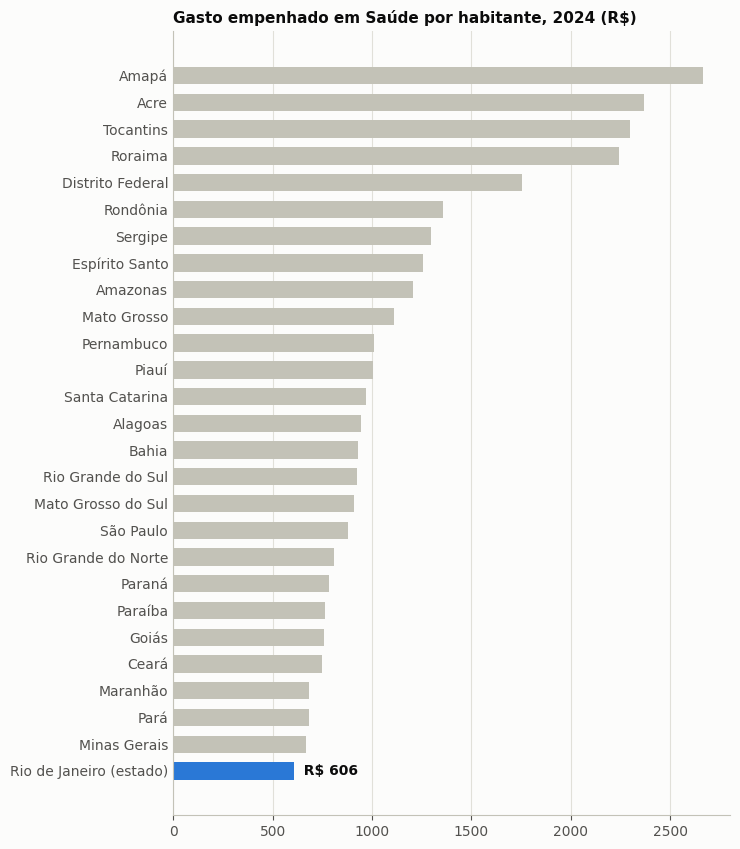

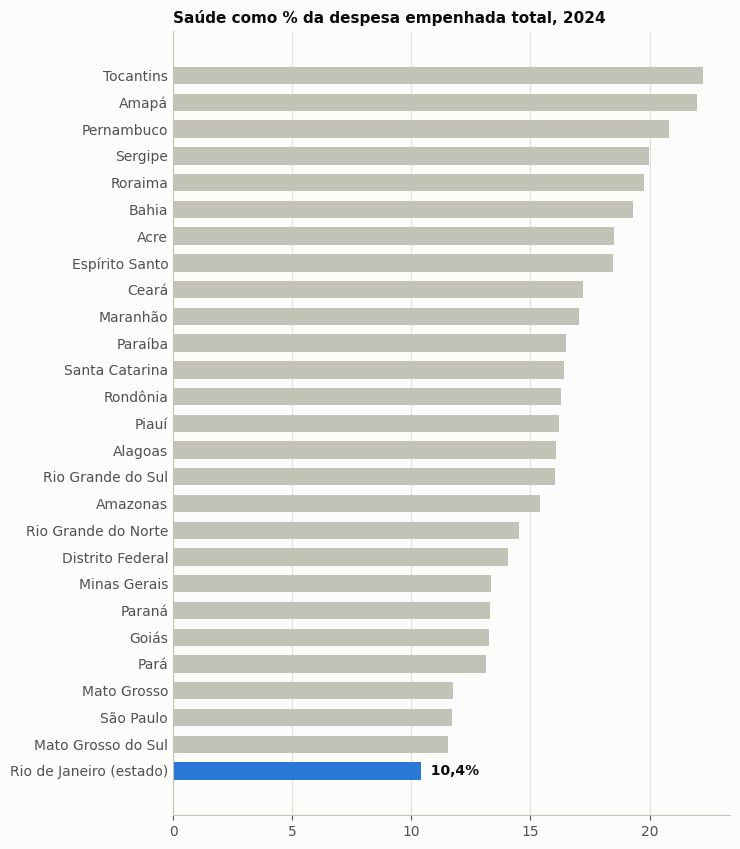

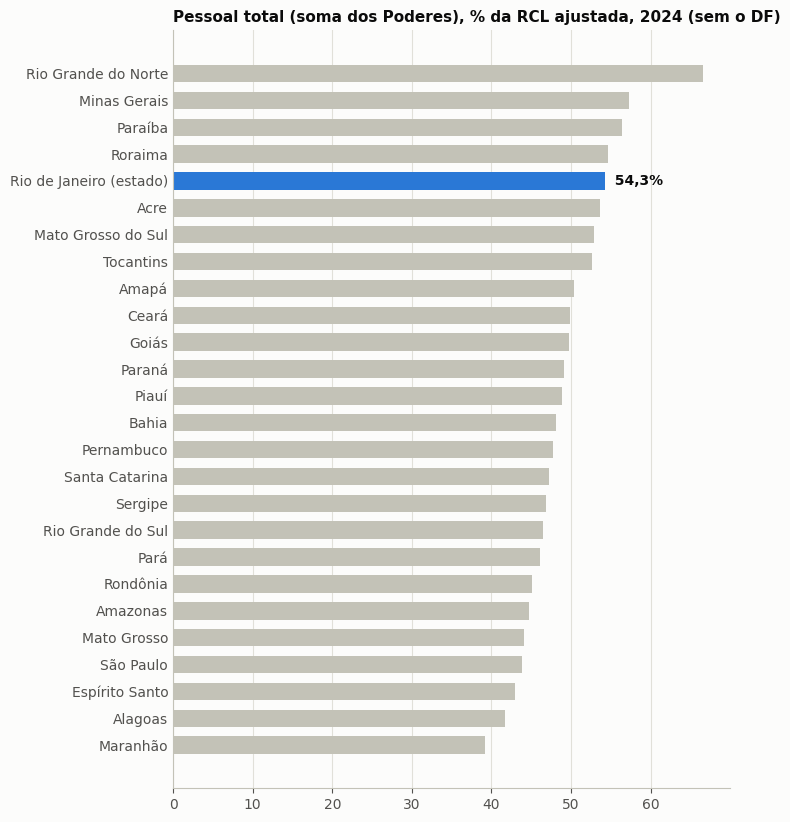

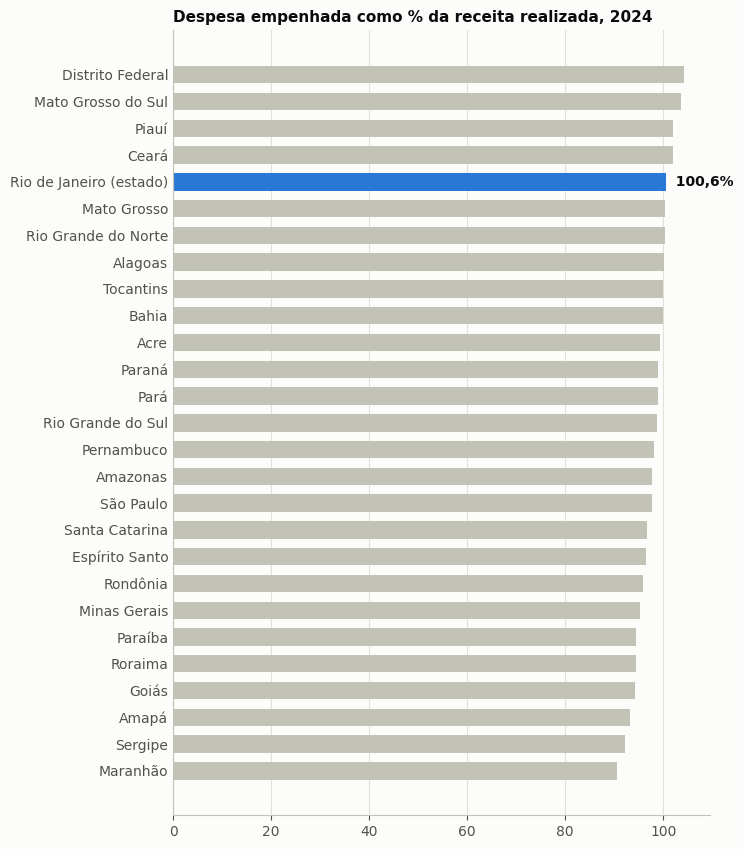

In [15]:
def barras(serie, titulo, nome_destaque, formato, rotulos):
    s = serie.dropna().sort_values()
    cores = [AZUL if rotulos[i] == nome_destaque else CINZA_CLARO for i in s.index]
    fig, ax = plt.subplots(figsize=(7.5, 0.27 * len(s) + 1.3))
    ax.barh([rotulos[i] for i in s.index], s.values, color=cores, height=0.65)
    for y, (i, v) in enumerate(s.items()):
        if rotulos[i] == nome_destaque:
            ax.text(v, y, "  " + formato(v), va="center", color=TEXTO, fontweight="bold")
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    plt.tight_layout()
    plt.show()


rot = est.nome.to_dict()
DEST = "Rio de Janeiro (estado)"
barras(est.saude_por_hab, "Gasto empenhado em Saúde por habitante, 2024 (R$)", DEST, lambda v: f"R$ {br(v, 0)}", rot)
barras(est.saude_pct_despesa, "Saúde como % da despesa empenhada total, 2024", DEST, lambda v: fmt_pct(v), rot)
barras(est_c.pessoal_total_pct_rcl, "Pessoal total (soma dos Poderes), % da RCL ajustada, 2024 (sem o DF)", DEST, lambda v: fmt_pct(v), rot)
barras(est.despesa_pct_receita, "Despesa empenhada como % da receita realizada, 2024", DEST, lambda v: fmt_pct(v), rot)

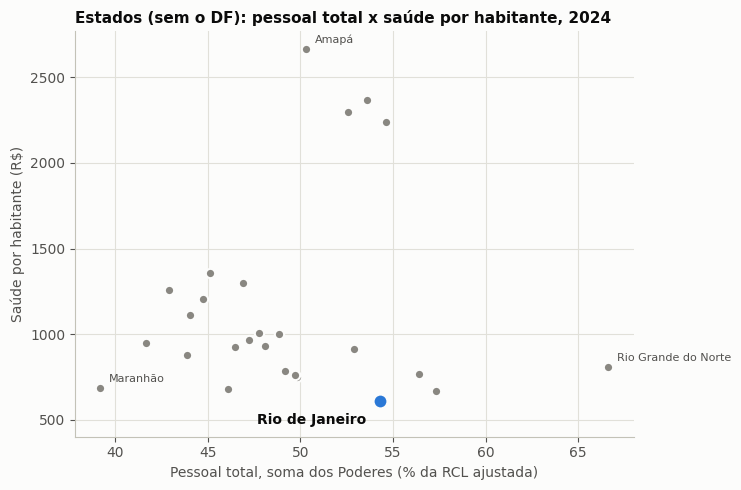

**Cautelas antes de concluir qualquer coisa:**

1. Cada estado classifica seus gastos por função de um jeito. **Não conferimos** se 'Saúde' tem o mesmo conteúdo em todos.
2. O DF acumula funções de estado e de município, o que pode explicar a posição dele em saúde por habitante (5º; **não confirmado**).
3. O RJ tem 1,7% de diferença entre os totais de despesa dos Anexos 01 e 02 (seção 5.1).
4. A população é a **estimativa 2024 do IBGE**; a do Siconfi não bate com nenhum ano do IBGE, e a escolha muda o menor e o maior município (ver docs/07, B1).
5. Despesa empenhada acima da receita realizada **não é necessariamente déficit**: o RREO tem outras linhas, como saldos de exercícios anteriores, que não olhamos.

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5))
outros = est_c.drop(COD_RJ)
ax.scatter(outros.pessoal_total_pct_rcl, outros.saude_por_hab, s=45, color=CINZA, edgecolor="#fcfcfb", linewidth=1.5)
rj = est_c.loc[COD_RJ]
ax.scatter([rj.pessoal_total_pct_rcl], [rj.saude_por_hab], s=110, color=AZUL, edgecolor="#fcfcfb", linewidth=2)
ax.annotate("Rio de Janeiro", (rj.pessoal_total_pct_rcl, rj.saude_por_hab), xytext=(-10, -16), ha="right", textcoords="offset points", color=TEXTO, fontweight="bold")
for i in [outros.saude_por_hab.idxmax(), outros.pessoal_total_pct_rcl.idxmax(), outros.pessoal_total_pct_rcl.idxmin()]:
    ax.annotate(est.nome[i], (est_c.pessoal_total_pct_rcl[i], est_c.saude_por_hab[i]), xytext=(6, 4), textcoords="offset points", color=TEXTO_2, fontsize=8)
ax.set_ylim(bottom=400)
ax.set_xlabel("Pessoal total, soma dos Poderes (% da RCL ajustada)")
ax.set_ylabel("Saúde por habitante (R$)")
ax.set_title("Estados (sem o DF): pessoal total x saúde por habitante, 2024")
plt.tight_layout()
plt.show()

texto("**Cautelas antes de concluir qualquer coisa:**\n\n"
      "1. Cada estado classifica seus gastos por função de um jeito. **Não conferimos** se 'Saúde' tem o mesmo conteúdo em todos.\n"
      f"2. O DF acumula funções de estado e de município, o que pode explicar a posição dele em saúde por habitante ({int(est.saude_por_hab.rank(ascending=False, method='min')['53'])}º; **não confirmado**).\n"
      f"3. O RJ tem {br(abs(t.loc[COD_RJ, 'despesa_anexo02'] / t.loc[COD_RJ, 'despesa'] - 1) * 100, 1)}% de diferença entre os totais de despesa dos Anexos 01 e 02 (seção 5.1).\n"
      "4. A população é a **estimativa 2024 do IBGE**; a do Siconfi não bate com nenhum ano do IBGE, e a escolha muda o menor e o maior município (ver docs/07, B1).\n"
      "5. Despesa empenhada acima da receita realizada **não é necessariamente déficit**: o RREO tem outras linhas, como saldos de exercícios anteriores, que não olhamos.")

> **Legenda.** **Mediana**: valor do meio entre os 27 estados. **Posição (1 = maior)**: 1 é o estado com o maior valor. **Saúde por habitante**: despesa empenhada na função Saúde dividida pela população. **Saúde, % da despesa**: fatia da despesa total que vai para a função Saúde. **Despesa, % da receita**: despesa empenhada ÷ receita realizada. **Barras azuis**: o RJ; **cinza**: os demais.

## 8. Os 92 municípios do RJ

In [17]:
mun = t[t.grupo == "Município do RJ"].copy()
IND_MUN = {"saude_por_hab": ("Saúde por habitante", fmt_rs), "saude_pct_despesa": ("Saúde, % da despesa total", fmt_pct),
           "receita_por_hab": ("Receita por habitante", fmt_rs), "despesa_pct_receita": ("Despesa, % da receita", fmt_pct),
           "pessoal_total_pct_rcl": ("Pessoal total (soma dos Poderes), % da RCL", fmt_pct)}
cap = mun.loc[COD_CAPITAL]
sem_esp = mun.drop(index=list(ATIPICOS))       # sem os 4 casos especiais (RCL atípica ou totais inconsistentes)
linhas = [{"Indicador": r, "Mediana": f(mun[c].median()),
           "Menor": com_nome(mun, c, f, "min"), "Maior": com_nome(mun, c, f, "max"),
           "Menor (sem casos especiais)": com_nome(sem_esp, c, f, "min"), "Maior (sem casos especiais)": com_nome(sem_esp, c, f, "max"),
           "Capital (Rio)": f"{f(cap[c])} ({int(mun[c].rank(ascending=False, method='min')[COD_CAPITAL])}º maior de {int(mun[c].notna().sum())})"}
          for c, (r, f) in IND_MUN.items()]
tabela_md(pd.DataFrame(linhas).set_index("Indicador"))
texto("**O que vemos (maior e menor).** A capital aparece com a posição entre os 92 (1º = maior valor). "
      "O **⚠** marca um maior ou menor valor que pertence a um caso especial (dado atípico, seções 5 e 9). Por isso a tabela mostra também o maior e o menor **sem** esses 4 municípios.\n\n"
      + "\n".join(f"- **{r}:** de {com_nome(mun, c, f, 'min')} a {com_nome(mun, c, f, 'max')}; "
                  f"sem os casos especiais, de {com_nome(sem_esp, c, f, 'min')} a {com_nome(sem_esp, c, f, 'max')}."
                  for c, (r, f) in IND_MUN.items()))

| Indicador | Mediana | Menor | Maior | Menor (sem casos especiais) | Maior (sem casos especiais) | Capital (Rio) |
|---|---|---|---|---|---|---|
| Saúde por habitante | R$ 2.319 | R$ 900 (São João de Meriti) | R$ 6.465 (São João da Barra) | R$ 900 (São João de Meriti) | R$ 6.465 (São João da Barra) | R$ 1.136 (85º maior de 92) |
| Saúde, % da despesa total | 29,0% | 15,3% (Maricá) | 47,9% (Bom Jesus do Itabapoana) | 15,3% (Maricá) | 47,9% (Bom Jesus do Itabapoana) | 19,3% (88º maior de 92) |
| Receita por habitante | R$ 8.175 | R$ 2.632 (São Gonçalo) | R$ 32.196 (Saquarema) | R$ 2.632 (São Gonçalo) | R$ 32.196 (Saquarema) | R$ 5.789 (71º maior de 92) |
| Despesa, % da receita | 102,1% | 83,6% (Saquarema) | 132,4% (Porciúncula) | 83,6% (Saquarema) | 132,4% (Porciúncula) | 100,8% (54º maior de 92) |
| Pessoal total (soma dos Poderes), % da RCL | 48,1% | 18,6% (Saquarema) | 159,7% (Areal ⚠) | 18,6% (Saquarema) | 66,1% (Seropédica) | 48,8% (46º maior de 92) |

**O que vemos (maior e menor).** A capital aparece com a posição entre os 92 (1º = maior valor). O **⚠** marca um maior ou menor valor que pertence a um caso especial (dado atípico, seções 5 e 9). Por isso a tabela mostra também o maior e o menor **sem** esses 4 municípios.

- **Saúde por habitante:** de R$ 900 (São João de Meriti) a R$ 6.465 (São João da Barra); sem os casos especiais, de R$ 900 (São João de Meriti) a R$ 6.465 (São João da Barra).
- **Saúde, % da despesa total:** de 15,3% (Maricá) a 47,9% (Bom Jesus do Itabapoana); sem os casos especiais, de 15,3% (Maricá) a 47,9% (Bom Jesus do Itabapoana).
- **Receita por habitante:** de R$ 2.632 (São Gonçalo) a R$ 32.196 (Saquarema); sem os casos especiais, de R$ 2.632 (São Gonçalo) a R$ 32.196 (Saquarema).
- **Despesa, % da receita:** de 83,6% (Saquarema) a 132,4% (Porciúncula); sem os casos especiais, de 83,6% (Saquarema) a 132,4% (Porciúncula).
- **Pessoal total (soma dos Poderes), % da RCL:** de 18,6% (Saquarema) a 159,7% (Areal ⚠); sem os casos especiais, de 18,6% (Saquarema) a 66,1% (Seropédica).

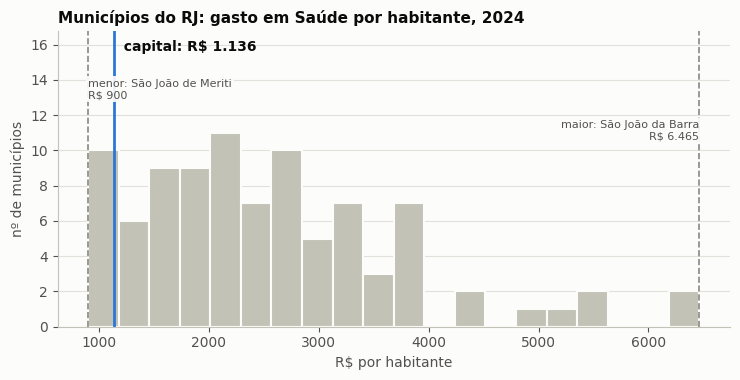

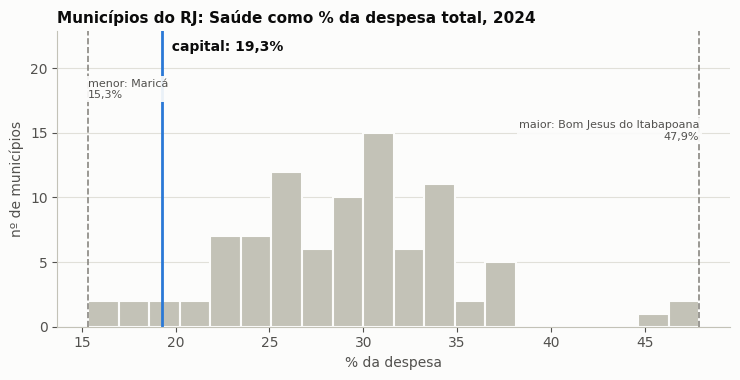

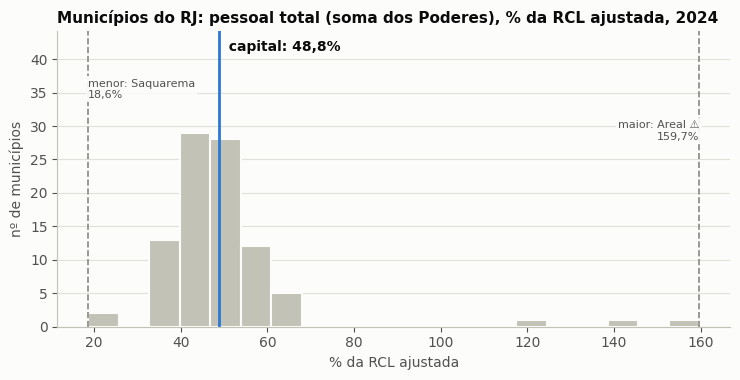

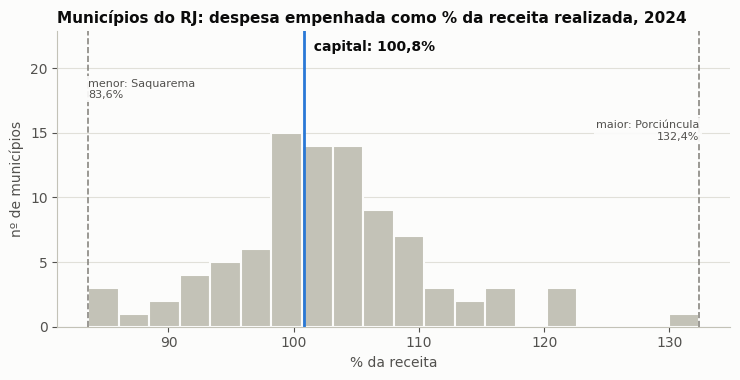

In [18]:
def histograma(serie, titulo, rotulo_x, marcar=None, formato=fmt_pct):
    fig, ax = plt.subplots(figsize=(7.5, 3.9))
    ax.hist(serie.dropna(), bins=20, color=CINZA_CLARO, edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.45)                 # espaço para os rótulos
    topo = ax.get_ylim()[1]
    if marcar is not None:
        ax.axvline(marcar, color=AZUL, linewidth=2)
        ax.text(marcar, topo * 0.97, "  capital: " + formato(marcar), color=TEXTO, fontweight="bold", va="top")
    s = serie.dropna()                                      # o menor e o maior, com o nome do município
    for qual, i, y, ha in (("menor", s.idxmin(), 0.84, "left"), ("maior", s.idxmax(), 0.70, "right")):
        aviso = " ⚠" if mun.loc[i, "flag_especial"] != "" else ""
        ax.axvline(s[i], color=CINZA, linewidth=1.2, linestyle="--")
        ax.text(s[i], topo * y, f"{qual}: {mun.loc[i, 'nome']}{aviso}\n{formato(s[i])}", ha=ha, va="top", fontsize=8, color=TEXTO_2,
                zorder=5, bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1.5, alpha=0.92))
    ax.set_title(titulo)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("nº de municípios")
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()


histograma(mun.saude_por_hab, "Municípios do RJ: gasto em Saúde por habitante, 2024", "R$ por habitante", cap.saude_por_hab, fmt_rs)
histograma(mun.saude_pct_despesa, "Municípios do RJ: Saúde como % da despesa total, 2024", "% da despesa", cap.saude_pct_despesa)
histograma(mun.pessoal_total_pct_rcl, "Municípios do RJ: pessoal total (soma dos Poderes), % da RCL ajustada, 2024", "% da RCL ajustada", cap.pessoal_total_pct_rcl)
histograma(mun.despesa_pct_receita, "Municípios do RJ: despesa empenhada como % da receita realizada, 2024", "% da receita", cap.despesa_pct_receita)

In [19]:
def extremos(col, rotulo, formato):
    ordem = mun.sort_values(col)
    d = pd.concat([ordem.head(5), ordem.tail(5)])
    d = d[["populacao", "relatorio_simplificado", "flag_especial", col]].copy()
    d.insert(0, "Posição", ["5 menores"] * 5 + ["5 maiores"] * 5)
    d = d.rename(columns={"populacao": "População", "relatorio_simplificado": "Simplificado?", "flag_especial": "Caso especial", col: rotulo})
    d["Caso especial"] = d["Caso especial"].replace("", "—")
    tabela_md(d.set_index(d.index.map(mun.nome)), {"População": fmt_int, rotulo: formato}, indice="Município")


extremos("saude_por_hab", "Saúde por habitante", fmt_rs)
extremos("saude_pct_despesa", "Saúde, % da despesa", fmt_pct)
extremos("pessoal_total_pct_rcl", "Pessoal total, % da RCL", fmt_pct)
extremos("despesa_pct_receita", "Despesa, % da receita", fmt_pct)

| Município | Posição | População | Simplificado? | Caso especial | Saúde por habitante |
|---|---|---:|---|---|---:|
| São João de Meriti | 5 menores | 466.536 | não | — | R$ 900 |
| São Pedro da Aldeia | 5 menores | 110.556 | não | — | R$ 949 |
| Queimados | 5 menores | 149.093 | não | — | R$ 1.003 |
| Nova Iguaçu | 5 menores | 843.046 | não | — | R$ 1.026 |
| São Gonçalo | 5 menores | 960.652 | não | — | R$ 1.065 |
| Maricá | 5 maiores | 211.986 | não | — | R$ 5.188 |
| Quissamã | 5 maiores | 23.126 | sim | — | R$ 5.521 |
| Arraial do Cabo | 5 maiores | 32.794 | não | — | R$ 5.525 |
| Carapebus | 5 maiores | 14.325 | não | — | R$ 6.391 |
| São João da Barra | 5 maiores | 38.708 | não | — | R$ 6.465 |

| Município | Posição | População | Simplificado? | Caso especial | Saúde, % da despesa |
|---|---|---:|---|---|---:|
| Maricá | 5 menores | 211.986 | não | — | 15,3% |
| Niterói | 5 menores | 516.720 | não | — | 15,6% |
| São Francisco de Itabapoana | 5 menores | 47.368 | não | — | 18,3% |
| Saquarema | 5 menores | 95.201 | não | — | 18,6% |
| Rio de Janeiro (capital) | 5 menores | 6.729.894 | não | — | 19,3% |
| Resende | 5 maiores | 137.612 | não | — | 37,9% |
| São Gonçalo | 5 maiores | 960.652 | não | — | 38,1% |
| Vassouras | 5 maiores | 35.904 | sim | — | 44,7% |
| Itaperuna | 5 maiores | 107.246 | não | RCL atípica | 46,4% |
| Bom Jesus do Itabapoana | 5 maiores | 37.172 | não | — | 47,9% |

| Município | Posição | População | Simplificado? | Caso especial | Pessoal total, % da RCL |
|---|---|---:|---|---|---:|
| Saquarema | 5 menores | 95.201 | não | — | 18,6% |
| Maricá | 5 menores | 211.986 | não | — | 20,2% |
| Volta Redonda | 5 menores | 279.898 | não | — | 33,6% |
| Paracambi | 5 menores | 43.656 | não | — | 33,6% |
| Sapucaia | 5 menores | 18.289 | não | — | 33,7% |
| Cabo Frio | 5 maiores | 238.166 | não | — | 64,1% |
| Seropédica | 5 maiores | 84.737 | não | — | 66,1% |
| Miracema | 5 maiores | 28.411 | não | RCL atípica | 122,3% |
| Itaperuna | 5 maiores | 107.246 | não | RCL atípica | 141,7% |
| Areal | 5 maiores | 12.236 | não | RCL atípica | 159,7% |

| Município | Posição | População | Simplificado? | Caso especial | Despesa, % da receita |
|---|---|---:|---|---|---:|
| Saquarema | 5 menores | 95.201 | não | — | 83,6% |
| Macaé | 5 menores | 264.138 | não | — | 85,4% |
| Armação dos Búzios | 5 menores | 42.442 | não | totais de despesa inconsistentes | 85,8% |
| Arraial do Cabo | 5 menores | 32.794 | não | — | 87,5% |
| Cardoso Moreira | 5 menores | 13.403 | não | — | 89,1% |
| Engenheiro Paulo de Frontin | 5 maiores | 12.648 | não | — | 117,4% |
| Barra do Piraí | 5 maiores | 98.501 | não | — | 122,1% |
| Cambuci | 5 maiores | 15.070 | não | — | 122,1% |
| Rio Bonito | 5 maiores | 59.113 | não | — | 122,2% |
| Porciúncula | 5 maiores | 17.832 | não | — | 132,4% |

In [20]:
rho = {g: d[["receita_por_hab", "saude_por_hab"]].corr(method="spearman").iloc[0, 1] for g, d in t.groupby("grupo")}
rho_pct = {g: d[["receita_por_hab", "saude_pct_despesa"]].corr(method="spearman").iloc[0, 1] for g, d in t.groupby("grupo")}
acima115 = mun[mun.despesa_pct_receita > 115]
tab = pd.DataFrame({"Receita/hab × saúde/hab": [br(rho[g], 2) for g in rho], "Receita/hab × saúde % da despesa": [br(rho_pct[g], 2) for g in rho_pct]},
                   index=list(rho))
tabela_md(tab, indice="Correlação de Spearman")
texto(f"**O que vemos.**\n\n"
      f"- **Saúde por habitante acompanha de perto a receita por habitante:** correlação de {br(rho['Estado'], 2)} nos estados e {br(rho['Município do RJ'], 2)} nos municípios. "
      f"Ou seja, quem tem mais receita por habitante gasta mais por habitante em saúde quase automaticamente.\n"
      f"- Já a **parcela** da despesa em saúde quase não acompanha a receita nos estados ({br(rho_pct['Estado'], 2)}) e é **negativa** nos municípios ({br(rho_pct['Município do RJ'], 2)}): "
      f"municípios com mais receita por habitante destinam uma fatia **menor** da despesa à saúde.\n"
      f"- Por isso, 'saúde por habitante' sozinho mede mais a **riqueza** do município do que a **prioridade** dada à saúde. A parcela da despesa é melhor para medir prioridade.\n"
      f"- Despesa sobre receita: mediana de {fmt_pct(mun.despesa_pct_receita.median())}, de {fmt_pct(mun.despesa_pct_receita.min())} a {fmt_pct(mun.despesa_pct_receita.max())}. "
      f"{len(acima115)} municípios passam de 115% ({', '.join(acima115.sort_values('despesa_pct_receita', ascending=False).nome)}). "
      f"A checagem A5 do Measure (docs/07) confirmou com a DCA que a despesa desses municípios existe. Cambuci e Itaboraí ficam explicados pelos saldos de exercícios anteriores usados. "
      f"**Barra do Piraí, Rio Bonito e Porciúncula seguem sem explicação** nos dados públicos que temos: é um ponto de atenção que pede apuração, e não uma conclusão sobre irregularidade. "
      f"{'Nenhum deles está' if not (set(acima115.index) & set(dif.index)) else 'Alguns deles estão'} entre os entes de total inconsistente da seção 5.1.\n"
      f"- Estados e municípios têm papéis e receitas diferentes na saúde (mediana de saúde por habitante: {fmt_rs(est.saude_por_hab.median())} nos estados e "
      f"{fmt_rs(mun.saude_por_hab.median())} nos municípios). **Não comparamos um grupo com o outro**, só dentro de cada grupo.")

| Correlação de Spearman | Receita/hab × saúde/hab | Receita/hab × saúde % da despesa |
|---|---|---|
| Estado | 0,80 | 0,09 |
| Município do RJ | 0,87 | -0,31 |

**O que vemos.**

- **Saúde por habitante acompanha de perto a receita por habitante:** correlação de 0,80 nos estados e 0,87 nos municípios. Ou seja, quem tem mais receita por habitante gasta mais por habitante em saúde quase automaticamente.
- Já a **parcela** da despesa em saúde quase não acompanha a receita nos estados (0,09) e é **negativa** nos municípios (-0,31): municípios com mais receita por habitante destinam uma fatia **menor** da despesa à saúde.
- Por isso, 'saúde por habitante' sozinho mede mais a **riqueza** do município do que a **prioridade** dada à saúde. A parcela da despesa é melhor para medir prioridade.
- Despesa sobre receita: mediana de 102,1%, de 83,6% a 132,4%. 7 municípios passam de 115% (Porciúncula, Rio Bonito, Cambuci, Barra do Piraí, Engenheiro Paulo de Frontin, Itaboraí, Carapebus). A checagem A5 do Measure (docs/07) confirmou com a DCA que a despesa desses municípios existe. Cambuci e Itaboraí ficam explicados pelos saldos de exercícios anteriores usados. **Barra do Piraí, Rio Bonito e Porciúncula seguem sem explicação** nos dados públicos que temos: é um ponto de atenção que pede apuração, e não uma conclusão sobre irregularidade. Nenhum deles está entre os entes de total inconsistente da seção 5.1.
- Estados e municípios têm papéis e receitas diferentes na saúde (mediana de saúde por habitante: R$ 946 nos estados e R$ 2.319 nos municípios). **Não comparamos um grupo com o outro**, só dentro de cada grupo.

> **Legenda.** **Capital (Rio)**: o município do Rio de Janeiro, mostrado como referência (não confundir com o estado). **Correlação de Spearman**: mede se duas coisas andam juntas pela ordem dos valores; vai de −1 (opostas) a +1 (juntas); perto de 0, sem relação. **Caso especial**: entes que mostramos "com e sem" na seção 9. **Simplificado?**: entrega relatório simplificado. **⚠**: o maior ou o menor valor pertence a um caso especial (dado atípico). **Posição da capital**: 1º é o município com o maior valor entre os 92.

## 9. Resultados com e sem os casos especiais
Por decisão do Matheus, os 4 municípios de dado atípico (RCL atípica ou totais inconsistentes) e os 12 de relatório simplificado **ficam na análise, marcados**, e mostramos o resultado **com e sem eles**.

In [21]:
cols = ["saude_por_hab", "saude_pct_despesa", "pessoal_total_pct_rcl", "despesa_pct_receita"]
sem_atip = mun.drop(index=list(ATIPICOS))
versoes = {"Todos os municípios": mun, "Sem os 4 de dado atípico": sem_atip, "Sem os 12 simplificados": mun[~mun.relatorio_simplificado],
           "Sem os atípicos e sem os simplificados": sem_atip[~sem_atip.relatorio_simplificado]}
tab = pd.DataFrame({nome: d[cols].median() for nome, d in versoes.items()}).T
tab.insert(0, "nº de municípios", [len(d) for d in versoes.values()])
tab.columns = ["nº de municípios", "Saúde por habitante", "Saúde, % da despesa", "Pessoal total, % da RCL", "Despesa, % da receita"]
tabela_md(tab, {"nº de municípios": fmt_int, "Saúde por habitante": fmt_rs, "Saúde, % da despesa": fmt_pct,
                "Pessoal total, % da RCL": fmt_pct, "Despesa, % da receita": fmt_pct}, indice="Mediana dos municípios")

variacao = (tab.iloc[1:, 1:].div(tab.iloc[0, 1:], axis=1) - 1).abs() * 100
pior = variacao.stack().idxmax()
maior_var = variacao.max().max()
qualif = "**muda pouco as medianas**" if maior_var < 5 else "**muda de forma relevante pelo menos uma mediana**"
texto(f"**O que vemos.** Tirar os casos especiais {qualif}: a maior variação em relação a 'todos' é de "
      f"{br(maior_var, 1)}% ({pior[1]}, versão '{pior[0]}'). Com os simplificados fora, a mediana de saúde por habitante vai de "
      f"{fmt_rs(tab.iloc[0, 1])} para {fmt_rs(tab.iloc[2, 1])}. A mediana é pouco sensível a casos extremos; as médias e os extremos seriam mais afetados.")

| Mediana dos municípios | nº de municípios | Saúde por habitante | Saúde, % da despesa | Pessoal total, % da RCL | Despesa, % da receita |
|---|---:|---:|---:|---:|---:|
| Todos os municípios | 92 | R$ 2.319 | 29,0% | 48,1% | 102,1% |
| Sem os 4 de dado atípico | 88 | R$ 2.282 | 29,3% | 46,7% | 102,0% |
| Sem os 12 simplificados | 80 | R$ 2.225 | 28,5% | 48,8% | 102,2% |
| Sem os atípicos e sem os simplificados | 76 | R$ 2.210 | 28,5% | 47,3% | 102,0% |

**O que vemos.** Tirar os casos especiais **muda pouco as medianas**: a maior variação em relação a 'todos' é de 4,7% (Saúde por habitante, versão 'Sem os atípicos e sem os simplificados'). Com os simplificados fora, a mediana de saúde por habitante vai de R$ 2.319 para R$ 2.225. A mediana é pouco sensível a casos extremos; as médias e os extremos seriam mais afetados.

In [22]:
# O RJ (estado) com e sem o DF (que acumula funções de estado e município e tem Poderes faltando)
sem_df = est.drop(index="53")
linhas, mudancas = [], []
for col, (rotulo, f) in IND_EST.items():
    base_c = est_c if col == "pessoal_total_pct_rcl" else est
    com = int(base_c[col].rank(ascending=False, method="min")[COD_RJ])
    sem = int(base_c.drop(index="53", errors="ignore")[col].rank(ascending=False, method="min")[COD_RJ])
    mudancas.append(abs(com - sem))
    linhas.append({"Indicador": rotulo, "Posição com o DF": f"{com}º de {len(base_c)}",
                   "Posição sem o DF": f"{sem}º de {len(base_c.drop(index='53', errors='ignore'))}"})
tabela_md(pd.DataFrame(linhas).set_index("Indicador"), indice="Posição do RJ entre os estados (1 = maior)")
texto(f"**O que vemos.** Quando o DF sai, a posição do RJ muda no máximo **{max(mudancas)} {'posição' if max(mudancas) == 1 else 'posições'}** entre os indicadores "
      f"({'não muda em nenhum' if max(mudancas) == 0 else 'muda em ' + str(sum(m > 0 for m in mudancas)) + ' de ' + str(len(mudancas))}). "
      "No indicador de pessoal total o DF já fica de fora por ter Poderes faltando.")

| Posição do RJ entre os estados (1 = maior) | Posição com o DF | Posição sem o DF |
|---|---|---|
| Saúde por habitante | 27º de 27 | 26º de 26 |
| Saúde, % da despesa total | 27º de 27 | 26º de 26 |
| Receita por habitante | 19º de 27 | 18º de 26 |
| Despesa, % da receita | 5º de 27 | 4º de 26 |
| Pessoal total (soma dos Poderes), % da RCL | 5º de 26 | 5º de 26 |
| Pessoal do Executivo, % da RCL | 6º de 27 | 6º de 26 |

**O que vemos.** Quando o DF sai, a posição do RJ muda no máximo **1 posição** entre os indicadores (muda em 4 de 6). No indicador de pessoal total o DF já fica de fora por ter Poderes faltando.

> **Legenda.** **Casos de dado atípico:** Areal, Itaperuna e Miracema (RCL muito abaixo da receita) e Armação dos Búzios (dois totais de despesa diferentes; a saúde dele foi corrigida pela DCA). **Simplificados:** os 12 municípios que entregam RREO e RGF simplificados. **Mediana**: pouco sensível a valores extremos, por isso é a medida usada nesta comparação.

## 10. Dívida e restos a pagar
Seção **descritiva**. Serve para ver se os dados permitem testar, no Analyze, a hipótese de que a receita está comprometida pela dívida. Nenhum teste é feito aqui.

In [23]:
# RGF Anexo 02 (dívida consolidada): o valor do período vem em colunas que mudam com a periodicidade do ente
# ("Até o 3º Quadrimestre" para quadrimestral, "Até o 2º Semestre" para semestral). Escolhemos a coluna do último período do ente.
d2 = rgf[rgf.anexo == "RGF-Anexo 02"].copy()
d2["coluna_alvo"] = "At. o " + d2.periodo.astype(str) + ". " + np.where(d2.periodicidade == "Q", "Quadrimestre", "Semestre")
d2 = d2[[re.fullmatch(a, c) is not None for a, c in zip(d2.coluna_alvo, d2.coluna)]]


def pegar_d2(cod_conta, nome):
    f = d2[d2.cod_conta == cod_conta]
    contagem = f.cod_ibge.value_counts()
    if (contagem > 1).any():
        print(f"ATENÇÃO {nome}: {int((contagem > 1).sum())} entes com mais de uma linha")
    return f.groupby("cod_ibge").valor.first().rename(nome)


t["dcl_pct_rcl"] = pegar_d2("PercentualDaDCLSobreARCL", "dcl_pct_rcl")
t["dc_pct_rcl"] = pegar_d2("PercentualDaDCSobreARCL", "dc_pct_rcl")
t["dcl"] = pegar_d2("DividaConsolidadaLiquida", "dcl")
t["limite_senado"] = pegar_d2("LimiteDefinidoPorResolucaoDoSenadoFederal", "limite_senado")
t["rcl_endividamento"] = pegar_d2("ReceitaCorrenteLiquidaAjustadaParaCalculoDosLimitesDeEndividamento", "rcl_endividamento")
# Alguns entes declaram o limite como PERCENTUAL (ex.: 120) em vez de valor em reais. Um valor pequeno demais para ser reais
# (menos de 1.000) é tratado como o próprio percentual. Verificado nos dados brutos em 21/10/2026.
t["limite_declarado_como_percentual"] = t.limite_senado < 1000
t["limite_dcl_pct"] = np.where(t.limite_declarado_como_percentual, t.limite_senado, t.limite_senado / t.rcl_endividamento * 100)
# Limite "fora do padrão" = diferente do valor mais comum declarado no grupo (sem supor o valor da lei, que não conferimos)
mais_comum = t.groupby("grupo").limite_dcl_pct.agg(lambda s: s.round(0).mode().iloc[0])
t["limite_dcl_fora_padrao"] = (t.limite_dcl_pct - t.grupo.map(mais_comum)).abs() > 1

# Restos a pagar (RREO Anexo 07): saldo total, sem intra-orçamentários
r7 = rreo[rreo.anexo == "RREO-Anexo 07"]
# A conta SaldoTotal traz uma linha por Poder e órgão; o total do ente (sem intra) é a linha "RESTOS A PAGAR (EXCETO INTRA-ORÇAMENTÁRIOS) (I)"
t["rp_saldo"] = pegar(r7, "SaldoTotal", r"Saldo Total L", "rp_saldo", conta="RESTOS A PAGAR (EXCETO INTRA-ORÇAMENTÁRIOS) (I)")
t["rp_pct_receita"] = t.rp_saldo / t.receita * 100
t["rp_por_hab"] = t.rp_saldo / t.populacao

campos = {"dcl_pct_rcl": "Dívida consolidada líquida, % da RCL", "limite_dcl_pct": "Limite do Senado declarado, % da RCL", "rp_saldo": "Saldo de restos a pagar"}
cobertura = pd.DataFrame({"Entes com o campo": [int(t[c].notna().sum()) for c in campos], "Total": [len(t)] * len(campos)}, index=list(campos.values()))
tabela_md(cobertura, {c: fmt_int for c in cobertura.columns}, indice="Campo")
faltam = {r: list(t[t[c].isna()].nome) for c, r in campos.items() if t[c].isna().any()}
if faltam:
    texto("**Entes sem o campo:** " + "; ".join(f"{r}: {', '.join(v)}" for r, v in faltam.items()))

| Campo | Entes com o campo | Total |
|---|---:|---:|
| Dívida consolidada líquida, % da RCL | 119 | 119 |
| Limite do Senado declarado, % da RCL | 117 | 119 |
| Saldo de restos a pagar | 118 | 119 |

**Entes sem o campo:** Limite do Senado declarado, % da RCL: Saquarema, Vassouras; Saldo de restos a pagar: Itatiaia

In [24]:
est = t[t.grupo == "Estado"]
tab = est.sort_values("dcl_pct_rcl", ascending=False)[["dcl_pct_rcl", "limite_dcl_pct", "rp_pct_receita"]].rename(columns={
    "dcl_pct_rcl": "Dívida líquida, % da RCL", "limite_dcl_pct": "Limite do Senado, % da RCL", "rp_pct_receita": "Restos a pagar, % da receita"})
tabela_md(tab.set_index(est.loc[tab.index, "nome"]), {c: fmt_pct for c in tab.columns}, destaque=["Rio de Janeiro (estado)"], indice="Estado (ordenado pela dívida)")

rjv = est.loc[COD_RJ]
pos_d = int(est.dcl_pct_rcl.rank(ascending=False, method="min")[COD_RJ])
pos_r = int(est.rp_pct_receita.rank(ascending=False, method="min")[COD_RJ])
texto(f"**O que vemos (estados).** A dívida consolidada líquida do RJ equivale a **{fmt_pct(rjv.dcl_pct_rcl)} da RCL** ({pos_d}º maior dos {est.dcl_pct_rcl.notna().sum()}; "
      f"mediana {fmt_pct(est.dcl_pct_rcl.median())}). O limite do Senado declarado pelo RJ equivale a {fmt_pct(rjv.limite_dcl_pct)} da RCL, "
      f"e a dívida líquida está **{'acima' if rjv.dcl_pct_rcl > rjv.limite_dcl_pct else 'abaixo'}** desse limite "
      f"({int((est.dcl_pct_rcl > est.limite_dcl_pct).sum())} estado(s) acima do próprio limite declarado, entre os que têm os dois dados). "
      f"Os restos a pagar são **{fmt_pct(rjv.rp_pct_receita)} da receita** do ano ({pos_r}º maior; mediana {fmt_pct(est.rp_pct_receita.median())}). "
      f"São valores **declarados**, ainda não conferidos com a lei, e esta seção não testa nenhuma hipótese.")

| Estado (ordenado pela dívida) | Dívida líquida, % da RCL | Limite do Senado, % da RCL | Restos a pagar, % da receita |
|---|---:|---:|---:|
| **Rio de Janeiro (estado)** | **211,3%** | **200,0%** | **0,6%** |
| Rio Grande do Sul | 184,7% | 200,0% | 2,1% |
| Minas Gerais | 162,6% | 200,0% | 6,6% |
| São Paulo | 126,5% | 200,0% | 0,9% |
| Alagoas | 75,8% | 200,0% | 0,9% |
| Piauí | 62,7% | 200,4% | 2,4% |
| Rio Grande do Norte | 40,2% | 200,0% | 1,7% |
| Bahia | 37,1% | 200,0% | 0,0% |
| Ceará | 33,1% | 200,0% | 0,4% |
| Pernambuco | 30,1% | 200,0% | 0,4% |
| Amazonas | 29,7% | 200,0% | 0,1% |
| Santa Catarina | 28,4% | 200,0% | 0,0% |
| Mato Grosso do Sul | 24,8% | 200,8% | 0,2% |
| Goiás | 24,3% | 200,0% | 1,2% |
| Acre | 19,8% | 200,0% | 3,0% |
| Distrito Federal | 13,1% | 200,0% | 0,4% |
| Sergipe | 11,6% | 200,0% | 0,2% |
| Tocantins | 10,9% | 200,0% | 2,0% |
| Roraima | 10,0% | 90,3% | 1,2% |
| Pará | 7,2% | 200,0% | 0,2% |
| Maranhão | 3,0% | 200,0% | 0,7% |
| Rondônia | -1,3% | 200,0% | 0,9% |
| Paraíba | -2,4% | 200,0% | 1,3% |
| Paraná | -5,1% | 200,0% | 1,6% |
| Amapá | -6,9% | 200,0% | 5,5% |
| Espírito Santo | -9,8% | 200,0% | 0,4% |
| Mato Grosso | -14,5% | 200,0% | 1,0% |

**O que vemos (estados).** A dívida consolidada líquida do RJ equivale a **211,3% da RCL** (1º maior dos 27; mediana 24,3%). O limite do Senado declarado pelo RJ equivale a 200,0% da RCL, e a dívida líquida está **acima** desse limite (1 estado(s) acima do próprio limite declarado, entre os que têm os dois dados). Os restos a pagar são **0,6% da receita** do ano (17º maior; mediana 0,9%). São valores **declarados**, ainda não conferidos com a lei, e esta seção não testa nenhuma hipótese.

In [25]:
mun = t[t.grupo == "Município do RJ"].copy()
linhas = []
for c, rotulo, f in [("dcl_pct_rcl", "Dívida líquida, % da RCL", fmt_pct), ("limite_dcl_pct", "Limite do Senado, % da RCL", fmt_pct),
                     ("rp_pct_receita", "Restos a pagar, % da receita", fmt_pct), ("rp_por_hab", "Restos a pagar por habitante", fmt_rs)]:
    linhas.append({"Indicador": rotulo, "Municípios com dado": int(mun[c].notna().sum()), "Mediana": f(mun[c].median()),
                   "Menor": com_nome(mun, c, f, "min"), "Maior": com_nome(mun, c, f, "max"), "Capital (Rio)": f(mun.loc[COD_CAPITAL, c])})
tabela_md(pd.DataFrame(linhas).set_index("Indicador"), {"Municípios com dado": fmt_int})

mun_ok = mun[mun.limite_dcl_pct.notna() & ~mun.limite_dcl_fora_padrao]
acima_lim = mun_ok[mun_ok.dcl_pct_rcl > mun_ok.limite_dcl_pct]
fora = t[t.limite_dcl_fora_padrao]
texto(f"**O que vemos (municípios).** Entre os {len(mun_ok)} municípios com limite declarado dentro do padrão do grupo, {len(acima_lim)} têm dívida líquida "
      f"acima do limite do Senado que declaram{': ' + ', '.join(acima_lim.nome) if 0 < len(acima_lim) <= 8 else ''}. "
      f"**Limites declarados fora do padrão, em estados e municípios** (os valores mais comuns são {fmt_pct(mais_comum['Estado'], 0)} nos estados e {fmt_pct(mais_comum['Município do RJ'], 0)} nos municípios): "
      + ("; ".join(f"{n} ({fmt_pct(v)})" for n, v in zip(fora.nome, fora.limite_dcl_pct)) if len(fora) else "nenhum")
      + ". Esses entes ficam de fora da contagem acima e **precisam de checagem**. "
      f"Além disso, {int(t.limite_declarado_como_percentual.sum())} entes ({', '.join(t[t.limite_declarado_como_percentual].nome)}) declararam o limite já como **percentual** "
      f"(valor {br(t[t.limite_declarado_como_percentual].limite_senado.iloc[0], 0)}) em vez de reais; tratamos esse valor como o percentual, e eles **entram** na contagem. "
      "Os 12 simplificados entregam o RGF por **semestre**, e a leitura da coluna do último período foi tratada no código (célula acima). "
      "**Os valores serão analisados no Analyze**, não aqui.")

| Indicador | Municípios com dado | Mediana | Menor | Maior | Capital (Rio) |
|---|---:|---|---|---|---|
| Dívida líquida, % da RCL | 92 | -5,6% | -285,8% (Seropédica) | 61,8% (Cabo Frio) | 48,7% |
| Limite do Senado, % da RCL | 90 | 120,0% | 21,3% (Carmo) | 126,7% (Paracambi) | 120,0% |
| Restos a pagar, % da receita | 91 | 1,8% | 0,0% (Trajano de Moraes) | 28,6% (Rio Bonito) | 0,1% |
| Restos a pagar por habitante | 91 | R$ 139 | R$ 1 (Trajano de Moraes) | R$ 2.797 (Carapebus) | R$ 6 |

**O que vemos (municípios).** Entre os 88 municípios com limite declarado dentro do padrão do grupo, 0 têm dívida líquida acima do limite do Senado que declaram. **Limites declarados fora do padrão, em estados e municípios** (os valores mais comuns são 200% nos estados e 120% nos municípios): Roraima (90,3%); Carmo (21,3%); Paracambi (126,7%). Esses entes ficam de fora da contagem acima e **precisam de checagem**. Além disso, 8 entes (Belford Roxo, Conceição de Macabu, Cordeiro, Duas Barras, Nova Iguaçu, São Fidélis, Sumidouro, Trajano de Moraes) declararam o limite já como **percentual** (valor 120) em vez de reais; tratamos esse valor como o percentual, e eles **entram** na contagem. Os 12 simplificados entregam o RGF por **semestre**, e a leitura da coluna do último período foi tratada no código (célula acima). **Os valores serão analisados no Analyze**, não aqui.

> **Legenda.** **DC / DCL**: dívida consolidada / dívida consolidada **líquida** (a dívida menos as disponibilidades de caixa e haveres, segundo o RGF). **Limite do Senado**: o RGF mostra o limite de endividamento definido por resolução do Senado; aqui o transformamos em % da RCL dividindo o limite pela RCL ajustada para endividamento. **Restos a pagar**: despesas empenhadas que **não foram pagas até o fim do ano**; usamos o saldo total (processados e não processados), sem intra-orçamentários. **Colunas do período**: "Até o 3º Quadrimestre" (entes quadrimestrais) ou "Até o 2º Semestre" (entes semestrais).

## 11. Resumo e pontos em aberto

In [26]:
est = t[t.grupo == "Estado"]
est_c = est[~est.poderes_incompletos]
rjv = est.loc[COD_RJ]
menor_saude = est.saude_por_hab.idxmin() == COD_RJ
capv = mun.loc[COD_CAPITAL]
n_mun = len(mun)
pos_sh = int(mun.saude_por_hab.rank(ascending=False, method="min")[COD_CAPITAL])
pos_sp = int(mun.saude_pct_despesa.rank(ascending=False, method="min")[COD_CAPITAL])
pos_rh = int(mun.receita_por_hab.rank(ascending=False, method="min")[COD_CAPITAL])
pos_rj_rh = int(est.receita_por_hab.rank(ascending=False, method="min")[COD_RJ])
texto("\n".join([
    "**O que os dados permitem**",
    "",
    "1. Comparar o RJ com os outros 26 estados e os 92 municípios entre si, em indicadores de gasto em saúde, pessoal, despesa, dívida e restos a pagar.",
    f"2. Descrever o RJ: {'**menor gasto em saúde por habitante** dos 27 estados' if menor_saude else 'gasto em saúde por habitante'} ({fmt_rs(rjv.saude_por_hab)}), "
    f"folha total de pessoal em **{fmt_pct(rjv.pessoal_total_pct_rcl)}** da RCL, despesa empenhada em {fmt_pct(rjv.despesa_pct_receita)} da receita realizada "
    f"e dívida líquida em {fmt_pct(rjv.dcl_pct_rcl)} da RCL.",
    "",
    "**Insight que deve acompanhar o trabalho: a capital e o gasto por habitante (sempre com a ressalva)**",
    "",
    f"- A capital gasta **{fmt_rs(capv.saude_por_hab)} por habitante** em saúde: o **{pos_sh}º maior entre os {n_mun}** municípios, ou seja, um dos {n_mun - pos_sh + 1} menores.",
    f"- **Isso, sozinho, não diz que a saúde da capital é pior.** Saúde por habitante acompanha a receita por habitante (correlação de {br(rho['Município do RJ'], 2)} nos municípios), "
    f"e a receita por habitante da capital ({fmt_rs(capv.receita_por_hab)}) é a {pos_rh}ª maior. O Siconfi mostra **gasto, não qualidade**.",
    f"- A fatia da despesa que a capital destina à saúde ({fmt_pct(capv.saude_pct_despesa)}) é a {pos_sp}ª maior. Nos municípios, quem tem mais receita por habitante tende a destinar fatia menor "
    f"(correlação de {br(rho_pct['Município do RJ'], 2)}), mas a capital não tem receita alta por habitante, então esse padrão **não explica** a fatia baixa dela. "
    "É uma **observação para o Analyze, não uma conclusão**.",
    f"- **O mesmo cuidado vale para o RJ (estado):** o menor gasto por habitante entre os estados convive com uma receita por habitante na {pos_rj_rh}ª posição (correlação de {br(rho['Estado'], 2)} entre receita e gasto em saúde por habitante).",
    "",
    "**O que a hipótese dos 5 Porquês (receita comprometida) encontra aqui**",
    "",
    "- Os indicadores de peso da folha de pessoal, de despesa sobre a receita, de dívida e de restos a pagar já estão na tabela, **mas a comparação formal é do Analyze**.",
    "- Os dados **não mostram causa**. Mostram a **posição** do RJ em relação aos outros estados.",
    "",
    "**O que os dados não permitem**",
    "",
    "- Dizer se algum ente cumpre o **mínimo legal de saúde**: o Anexo 12 do RREO volta vazio no Siconfi, e a fonte alternativa (SIOPS) estava fora do ar em 21/10/2026. "
    "**O nosso indicador de saúde como % da despesa não é o mínimo legal**, que usa outra base (receita de impostos e transferências).",
    "- Dizer que um lugar tem “melhor saúde”: o Siconfi mostra gasto, não qualidade.",
    "- Tirar conclusão dos 4 casos de dado atípico sem checagem (seção 5).",
    "",
    "**Decisões já tomadas (Matheus)**",
    "",
    "1. **Pessoal:** indicador principal = soma dos Poderes; o Executivo fica como referência dos limites.",
    "2. **Dados atípicos e os 12 simplificados:** mantidos, marcados, com resultado “com e sem” (seção 9).",
    "3. **Dívida e restos a pagar:** coletados; o teste da hipótese fica para o Analyze.",
    "4. **Mínimo de saúde:** o núcleo segue sem ele. **Lembrete:** ao terminar o núcleo, testar o SIOPS de novo.",
    "",
    "**Pontos em aberto**",
    "",
    "- Ano de referência da população do Siconfi (não confirmado).",
    "- Regra de quem pode entregar o relatório simplificado (não confirmada).",
    "- Fundamento legal da RCL ajustada e dos limites de pessoal (não conferido na lei).",
    "- Se a Defensoria deveria aparecer nos Poderes do RJ.",
    "- O que explica as despesas acima de 115% da receita em alguns municípios.",
]))

**O que os dados permitem**

1. Comparar o RJ com os outros 26 estados e os 92 municípios entre si, em indicadores de gasto em saúde, pessoal, despesa, dívida e restos a pagar.
2. Descrever o RJ: **menor gasto em saúde por habitante** dos 27 estados (R$ 606), folha total de pessoal em **54,3%** da RCL, despesa empenhada em 100,6% da receita realizada e dívida líquida em 211,3% da RCL.

**Insight que deve acompanhar o trabalho: a capital e o gasto por habitante (sempre com a ressalva)**

- A capital gasta **R$ 1.136 por habitante** em saúde: o **85º maior entre os 92** municípios, ou seja, um dos 8 menores.
- **Isso, sozinho, não diz que a saúde da capital é pior.** Saúde por habitante acompanha a receita por habitante (correlação de 0,87 nos municípios), e a receita por habitante da capital (R$ 5.789) é a 71ª maior. O Siconfi mostra **gasto, não qualidade**.
- A fatia da despesa que a capital destina à saúde (19,3%) é a 88ª maior. Nos municípios, quem tem mais receita por habitante tende a destinar fatia menor (correlação de -0,31), mas a capital não tem receita alta por habitante, então esse padrão **não explica** a fatia baixa dela. É uma **observação para o Analyze, não uma conclusão**.
- **O mesmo cuidado vale para o RJ (estado):** o menor gasto por habitante entre os estados convive com uma receita por habitante na 19ª posição (correlação de 0,80 entre receita e gasto em saúde por habitante).

**O que a hipótese dos 5 Porquês (receita comprometida) encontra aqui**

- Os indicadores de peso da folha de pessoal, de despesa sobre a receita, de dívida e de restos a pagar já estão na tabela, **mas a comparação formal é do Analyze**.
- Os dados **não mostram causa**. Mostram a **posição** do RJ em relação aos outros estados.

**O que os dados não permitem**

- Dizer se algum ente cumpre o **mínimo legal de saúde**: o Anexo 12 do RREO volta vazio no Siconfi, e a fonte alternativa (SIOPS) estava fora do ar em 21/10/2026. **O nosso indicador de saúde como % da despesa não é o mínimo legal**, que usa outra base (receita de impostos e transferências).
- Dizer que um lugar tem “melhor saúde”: o Siconfi mostra gasto, não qualidade.
- Tirar conclusão dos 4 casos de dado atípico sem checagem (seção 5).

**Decisões já tomadas (Matheus)**

1. **Pessoal:** indicador principal = soma dos Poderes; o Executivo fica como referência dos limites.
2. **Dados atípicos e os 12 simplificados:** mantidos, marcados, com resultado “com e sem” (seção 9).
3. **Dívida e restos a pagar:** coletados; o teste da hipótese fica para o Analyze.
4. **Mínimo de saúde:** o núcleo segue sem ele. **Lembrete:** ao terminar o núcleo, testar o SIOPS de novo.

**Pontos em aberto**

- Ano de referência da população do Siconfi (não confirmado).
- Regra de quem pode entregar o relatório simplificado (não confirmada).
- Fundamento legal da RCL ajustada e dos limites de pessoal (não conferido na lei).
- Se a Defensoria deveria aparecer nos Poderes do RJ.
- O que explica as despesas acima de 115% da receita em alguns municípios.

## 12. Salvar a tabela de indicadores

In [27]:
saida = PASTA.parent / "dados_tratados"
saida.mkdir(exist_ok=True)
t.reset_index().to_csv(saida / "indicadores_2024.csv", index=False, encoding="utf-8-sig")
texto(f"Gravado: `dados_tratados/indicadores_2024.csv` ({len(t)} entes, {t.shape[1] + 1} colunas).")

Gravado: `dados_tratados/indicadores_2024.csv` (119 entes, 49 colunas).

## 13. Glossário e dicionário de colunas

### 13.1 Siglas e termos

| Sigla ou termo | Significado |
|---|---|
| **Siconfi** | Sistema de Informações Contábeis e Fiscais do Setor Público Brasileiro (Tesouro Nacional). Fonte de todos os números deste notebook |
| **RREO** | Relatório Resumido da Execução Orçamentária (bimestral). Usamos o 6º bimestre, que acumula o ano |
| **RGF** | Relatório de Gestão Fiscal (quadrimestral; semestral nos municípios simplificados) |
| **LRF** | Lei de Responsabilidade Fiscal |
| **RCL** | Receita corrente líquida: base dos limites de pessoal e de endividamento |
| **RCL ajustada** | RCL menos transferências da União ligadas a emendas individuais e de bancada (seção 5.4) |
| **DTP** | Despesa total com pessoal |
| **DC / DCL** | Dívida consolidada / dívida consolidada líquida |
| **Empenhada** | Despesa comprometida no orçamento; não é o mesmo que paga |
| **Intra-orçamentárias** | Despesas entre órgãos do mesmo governo; ficam de fora para não duplicar |
| **Restos a pagar** | Despesas empenhadas e não pagas até o fim do ano |
| **Poder** | Executivo, Legislativo, Judiciário, Ministério Público ou Defensoria |
| **Limite prudencial / máximo** | Limites de pessoal que o ente declara no RGF; o prudencial é 95% do máximo |
| **ASPS** | Ações e serviços públicos de saúde (base do mínimo legal de saúde; **não usado** aqui) |
| **SIOPS** | Sistema do Ministério da Saúde com o mínimo legal de saúde. Estava fora do ar em 21/10/2026 |
| **DF** | Distrito Federal (acumula funções de estado e de município) |
| **UF** | Unidade da Federação (estado ou DF) |
| **p.p.** | Ponto percentual |
| **Mediana** | Valor do meio quando os entes são ordenados |
| **Correlação de Spearman** | Mede se duas coisas andam juntas pela ordem dos valores (−1 a +1) |
| **Anexo 12 do RREO** | Demonstrativo da saúde (mínimo legal). Volta vazio na API do Siconfi |

In [28]:
DICIONARIO = {
    "cod_ibge": "Código IBGE do ente (2 dígitos para estado, 7 para município)",
    "ente": "Nome do ente no cadastro do Siconfi",
    "esfera": "Esfera: E (estado), D (Distrito Federal), M (município)",
    "grupo": "Estado ou Município do RJ",
    "relatorio_simplificado": "Entregou RREO e RGF simplificados (sim/não)",
    "populacao": "População do ente, estimativa 2024 do IBGE (SIDRA, tabela 6579)",
    "populacao_siconfi": "População do campo `populacao` do Siconfi (origem não confirmada; só sensibilidade)",
    "saude_rreo": "Saúde do RREO Anexo 02, antes da correção de Búzios pela DCA (R$)",
    "despesa_base_saude": "Denominador da fatia da saúde: total do Anexo 02 (em Búzios, Anexo 01) (R$)",
    "nome": "Nome de exibição (distingue o estado e a capital do RJ)",
    "receita": "Receita realizada no ano, sem intra-orçamentárias (R$)",
    "despesa": "Despesa empenhada no ano, sem intra-orçamentárias, do Anexo 01 (R$)",
    "saude": "Despesa empenhada na função Saúde, sem intra-orçamentárias (R$)",
    "saude_pct_declarado": "% de Saúde que o ente declara, com base no total com intra-orçamentárias",
    "despesa_anexo02": "Total de despesa do Anexo 02, sem intra-orçamentárias (R$)",
    "despesa_total_anexo02": "Total de despesa do Anexo 02, com intra-orçamentárias (R$)",
    "pessoal": "Despesa total com pessoal do Poder Executivo (R$)",
    "pessoal_pct_rcl": "Pessoal do Executivo como % da RCL ajustada, calculado pelo ente",
    "limite_max_pct": "Limite máximo de pessoal do Executivo, % da RCL, como declarado",
    "limite_prudencial_pct": "Limite prudencial de pessoal do Executivo, % da RCL, como declarado",
    "rcl_bruta": "RCL antes do ajuste (R$)",
    "rcl_ajustada": "RCL ajustada (R$), base dos limites de pessoal",
    "ded_emendas_ind": "Dedução: transferências da União, emendas individuais (R$)",
    "ded_emendas_bancada": "Dedução: transferências da União, emendas de bancada (R$)",
    "ded_acs": "Dedução: transferências da União, remuneração de agentes comunitários de saúde (R$)",
    "pessoal_total": "Pessoal de todos os Poderes somados (R$)",
    "n_poderes": "Quantos Poderes têm dado no RGF",
    "pessoal_total_pct_rcl": "Pessoal total como % da RCL ajustada (indicador principal de pessoal)",
    "poderes_incompletos": "Faltam Poderes no RGF (a soma de pessoal fica subestimada)",
    "saude_por_hab": "Saúde ÷ população (R$ por habitante)",
    "receita_por_hab": "Receita ÷ população (R$ por habitante)",
    "saude_pct_despesa": "Saúde ÷ total de despesa do Anexo 02 (sem intra) × 100",
    "despesa_pct_receita": "Despesa ÷ receita × 100",
    "folga_pessoal_pp": "Limite máximo menos pessoal do Executivo, em pontos percentuais",
    "flag_especial": "Marca dos casos tratados 'com e sem' (RCL atípica; totais inconsistentes)",
    "rcl_sobre_receita": "RCL ajustada ÷ receita realizada",
    "acima_prudencial": "Pessoal do Executivo acima do limite prudencial declarado (sim/não)",
    "acima_maximo": "Pessoal do Executivo acima do limite máximo declarado (sim/não)",
    "dcl_pct_rcl": "Dívida consolidada líquida como % da RCL ajustada para endividamento",
    "dc_pct_rcl": "Dívida consolidada como % da RCL ajustada para endividamento",
    "dcl": "Dívida consolidada líquida (R$)",
    "limite_senado": "Limite de endividamento definido por resolução do Senado, como declarado (R$)",
    "rcl_endividamento": "RCL ajustada para cálculo dos limites de endividamento (R$)",
    "limite_dcl_pct": "Limite do Senado como % da RCL (limite ÷ RCL de endividamento)",
    "limite_dcl_fora_padrao": "Limite declarado diferente do valor mais comum do grupo (precisa de checagem)",
    "limite_declarado_como_percentual": "O ente declarou o limite do Senado já como percentual (ex.: 120) e não em reais",
    "rp_saldo": "Saldo total de restos a pagar, sem intra-orçamentários (R$)",
    "rp_pct_receita": "Restos a pagar ÷ receita realizada × 100",
    "rp_por_hab": "Restos a pagar ÷ população (R$ por habitante)",
}
sem_descricao = [c for c in ["cod_ibge"] + list(t.columns) if c not in DICIONARIO]
assert not sem_descricao, f"colunas sem descrição no dicionário: {sem_descricao}"
tabela_md(pd.DataFrame({"O que é": [DICIONARIO[c] for c in ["cod_ibge"] + list(t.columns)]}, index=["cod_ibge"] + list(t.columns)), indice="Coluna de indicadores_2024.csv")
texto(f"*Todas as {len(t.columns) + 1} colunas do arquivo estão descritas acima (conferido por código).*")

| Coluna de indicadores_2024.csv | O que é |
|---|---|
| cod_ibge | Código IBGE do ente (2 dígitos para estado, 7 para município) |
| ente | Nome do ente no cadastro do Siconfi |
| esfera | Esfera: E (estado), D (Distrito Federal), M (município) |
| grupo | Estado ou Município do RJ |
| relatorio_simplificado | Entregou RREO e RGF simplificados (sim/não) |
| populacao_siconfi | População do campo `populacao` do Siconfi (origem não confirmada; só sensibilidade) |
| populacao | População do ente, estimativa 2024 do IBGE (SIDRA, tabela 6579) |
| nome | Nome de exibição (distingue o estado e a capital do RJ) |
| receita | Receita realizada no ano, sem intra-orçamentárias (R$) |
| despesa | Despesa empenhada no ano, sem intra-orçamentárias, do Anexo 01 (R$) |
| saude | Despesa empenhada na função Saúde, sem intra-orçamentárias (R$) |
| saude_pct_declarado | % de Saúde que o ente declara, com base no total com intra-orçamentárias |
| despesa_anexo02 | Total de despesa do Anexo 02, sem intra-orçamentárias (R$) |
| despesa_total_anexo02 | Total de despesa do Anexo 02, com intra-orçamentárias (R$) |
| pessoal | Despesa total com pessoal do Poder Executivo (R$) |
| pessoal_pct_rcl | Pessoal do Executivo como % da RCL ajustada, calculado pelo ente |
| limite_max_pct | Limite máximo de pessoal do Executivo, % da RCL, como declarado |
| limite_prudencial_pct | Limite prudencial de pessoal do Executivo, % da RCL, como declarado |
| rcl_bruta | RCL antes do ajuste (R$) |
| rcl_ajustada | RCL ajustada (R$), base dos limites de pessoal |
| ded_emendas_ind | Dedução: transferências da União, emendas individuais (R$) |
| ded_emendas_bancada | Dedução: transferências da União, emendas de bancada (R$) |
| ded_acs | Dedução: transferências da União, remuneração de agentes comunitários de saúde (R$) |
| pessoal_total | Pessoal de todos os Poderes somados (R$) |
| n_poderes | Quantos Poderes têm dado no RGF |
| pessoal_total_pct_rcl | Pessoal total como % da RCL ajustada (indicador principal de pessoal) |
| poderes_incompletos | Faltam Poderes no RGF (a soma de pessoal fica subestimada) |
| saude_rreo | Saúde do RREO Anexo 02, antes da correção de Búzios pela DCA (R$) |
| despesa_base_saude | Denominador da fatia da saúde: total do Anexo 02 (em Búzios, Anexo 01) (R$) |
| saude_por_hab | Saúde ÷ população (R$ por habitante) |
| receita_por_hab | Receita ÷ população (R$ por habitante) |
| saude_pct_despesa | Saúde ÷ total de despesa do Anexo 02 (sem intra) × 100 |
| despesa_pct_receita | Despesa ÷ receita × 100 |
| folga_pessoal_pp | Limite máximo menos pessoal do Executivo, em pontos percentuais |
| flag_especial | Marca dos casos tratados 'com e sem' (RCL atípica; totais inconsistentes) |
| rcl_sobre_receita | RCL ajustada ÷ receita realizada |
| acima_prudencial | Pessoal do Executivo acima do limite prudencial declarado (sim/não) |
| acima_maximo | Pessoal do Executivo acima do limite máximo declarado (sim/não) |
| dcl_pct_rcl | Dívida consolidada líquida como % da RCL ajustada para endividamento |
| dc_pct_rcl | Dívida consolidada como % da RCL ajustada para endividamento |
| dcl | Dívida consolidada líquida (R$) |
| limite_senado | Limite de endividamento definido por resolução do Senado, como declarado (R$) |
| rcl_endividamento | RCL ajustada para cálculo dos limites de endividamento (R$) |
| limite_declarado_como_percentual | O ente declarou o limite do Senado já como percentual (ex.: 120) e não em reais |
| limite_dcl_pct | Limite do Senado como % da RCL (limite ÷ RCL de endividamento) |
| limite_dcl_fora_padrao | Limite declarado diferente do valor mais comum do grupo (precisa de checagem) |
| rp_saldo | Saldo total de restos a pagar, sem intra-orçamentários (R$) |
| rp_pct_receita | Restos a pagar ÷ receita realizada × 100 |
| rp_por_hab | Restos a pagar ÷ população (R$ por habitante) |

*Todas as 49 colunas do arquivo estão descritas acima (conferido por código).*

### 13.2 Limites desta análise
- Um ano só (2024), e só o último período de cada relatório.
- Os valores são o que cada ente **declarou**. Não foram auditados.
- Limites de pessoal e de dívida são os **declarados** pelos entes, não conferidos com a lei.
- O Siconfi mostra **gasto, não qualidade** do atendimento. Nenhum indicador aqui mede se a saúde de um lugar é boa ou ruim.
- O **mínimo legal de saúde não está nesta análise** (fonte alternativa indisponível em 21/10/2026).
- Comparações valem **dentro de cada grupo** (estados entre si, municípios entre si).